In [1]:
# Cell 0 — Imports
from __future__ import annotations

import os
import re
import json
from pathlib import Path
from typing import Any, Dict, Optional, Tuple, List

import pandas as pd


In [2]:
# Cell 1 — Configure paths (notebook sits next to save/ and save_grouped/)
ROOT = Path(".").resolve()

# ── Experiment directories ──────────────────────────────────────────────────
# Each entry is (path, human-readable label).
# Labels are used to separate runs in all plots — add Exp3 when ready.
SAVE_DIR_CONFIGS = [
    (ROOT / "save_pruning_logs_layer_by_layer_l2_profiling_5epochs/final",
     "layer_by_layer_exp1"),
    #(ROOT / "../save_pruning_logs_global/global","global_exp1"),
    # Uncomment and adjust when Exp3 logs are ready:
    (ROOT / "save_pruning_logs_layer_by_layer_uniform_global/final",  "layer_by_layer_globally_uniform"),
    (ROOT / "save_pruning_logs_layer_by_layer_cost_based_with_limit_retest_correct/final", "layer_by_layer_most_costly_layers_only"),
]

SAVE_DIRS  = [p for p, _ in SAVE_DIR_CONFIGS]
DIR_LABELS = {str(p.resolve()): label for p, label in SAVE_DIR_CONFIGS}

for p, label in SAVE_DIR_CONFIGS:
    print(f"[{label}]  exists={p.exists()}  path={p}")


[layer_by_layer_exp1]  exists=True  path=/home/jovyan/cost-based-pruning-layer-by-layer/save_pruning_logs_layer_by_layer_l2_profiling_5epochs/final
[layer_by_layer_globally_uniform]  exists=True  path=/home/jovyan/cost-based-pruning-layer-by-layer/save_pruning_logs_layer_by_layer_uniform_global/final
[layer_by_layer_most_costly_layers_only]  exists=True  path=/home/jovyan/cost-based-pruning-layer-by-layer/save_pruning_logs_layer_by_layer_cost_based_with_limit_retest_correct/final


In [3]:
# Cell 2 — Find all log.txt files
def find_logs(save_dirs: List[Path]) -> List[Path]:
    logs: List[Path] = []
    for base in save_dirs:
        if not base.exists():
            continue
        logs.extend(base.rglob("log.txt"))
    # deterministic order
    logs = sorted(set(logs), key=lambda p: str(p).lower())
    return logs

# Build (log_path, strategy_label) pairs so we never lose which dir a log came from
def find_logs_labeled(save_dir_configs):
    """Return list of (Path, label) for every log.txt found."""
    results = []
    for base, label in save_dir_configs:
        if not base.exists():
            continue
        for p in sorted(base.rglob("log.txt"), key=lambda x: str(x).lower()):
            results.append((p, label))
    # deduplicate by resolved path
    seen = set()
    deduped = []
    for p, label in results:
        rp = str(p.resolve())
        if rp not in seen:
            seen.add(rp)
            deduped.append((p, label))
    return deduped

log_path_label_pairs = find_logs_labeled(SAVE_DIR_CONFIGS)
log_paths = [p for p, _ in log_path_label_pairs]   # backward-compat alias

print(f"Found {len(log_paths)} log.txt files")
for p, lbl in log_path_label_pairs:
    print(f"  [{lbl}]  {p}")


Found 101 log.txt files
  [layer_by_layer_exp1]  /home/jovyan/cost-based-pruning-layer-by-layer/save_pruning_logs_layer_by_layer_l2_profiling_5epochs/final/test/final-07/log.txt
  [layer_by_layer_exp1]  /home/jovyan/cost-based-pruning-layer-by-layer/save_pruning_logs_layer_by_layer_l2_profiling_5epochs/final/test/final-08/log.txt
  [layer_by_layer_exp1]  /home/jovyan/cost-based-pruning-layer-by-layer/save_pruning_logs_layer_by_layer_l2_profiling_5epochs/final/test/final-09/log.txt
  [layer_by_layer_exp1]  /home/jovyan/cost-based-pruning-layer-by-layer/save_pruning_logs_layer_by_layer_l2_profiling_5epochs/final/test/final-10/log.txt
  [layer_by_layer_exp1]  /home/jovyan/cost-based-pruning-layer-by-layer/save_pruning_logs_layer_by_layer_l2_profiling_5epochs/final/test/final-11/log.txt
  [layer_by_layer_exp1]  /home/jovyan/cost-based-pruning-layer-by-layer/save_pruning_logs_layer_by_layer_l2_profiling_5epochs/final/test/final-12/log.txt
  [layer_by_layer_exp1]  /home/jovyan/cost-based-pru

In [4]:
import os
import re
import json
from pathlib import Path
import pandas as pd
import numpy as np

# ----------------------------
# Small parsing utilities
# ----------------------------

PARTS = ["inc", "down1", "down2", "down3", "down4", "up1", "up2", "up3", "up4", "outc", "other"]

GROUP_PARTS = {
    "encoder":    ["inc", "down1", "down2", "down3"],
    "bottleneck": ["down4"],
    "decoder":    ["up1", "up2", "up3", "up4", "outc"],
}

def _to_int_commas(x: str):
    if x is None:
        return np.nan
    x = x.strip().replace(",", "")
    return int(x) if x.isdigit() or (x and x[0] == "-" and x[1:].isdigit()) else np.nan

def _to_float(x: str):
    try:
        return float(x)
    except Exception:
        return np.nan

def _parse_g_token(tok: str):
    # "1.906G" -> 1.906
    if tok is None:
        return np.nan
    tok = tok.strip()
    m = re.match(r"^([+-]?\d+(?:\.\d+)?)G$", tok)
    return float(m.group(1)) if m else np.nan

def _parse_pct_token(tok: str):
    # "98.26%" or "nan%"
    if tok is None:
        return np.nan
    tok = tok.strip().replace("%", "")
    if tok.lower() == "nan":
        return np.nan
    return _to_float(tok)

def _extract_args_block(text: str):
    """
    Extracts the JSON dict after 'Args: {' ... '}'.
    Uses brace counting so it works even if the args span many lines.
    """
    anchor = "Args:"
    i = text.find(anchor)
    if i < 0:
        return {}
    j = text.find("{", i)
    if j < 0:
        return {}
    depth = 0
    end = None
    for k in range(j, len(text)):
        if text[k] == "{":
            depth += 1
        elif text[k] == "}":
            depth -= 1
            if depth == 0:
                end = k + 1
                break
    if end is None:
        return {}
    blob = text[j:end]
    try:
        return json.loads(blob)
    except Exception:
        return {}

def _infer_experiment_type(args: dict):
    scope = (args.get("scope") or "").lower().strip()
    if scope in {"global", "encoder", "decoder", "bottleneck", "custom_seq"}:
        return scope
    if "prune_channels" in args and args["prune_channels"] is not None:
        return "global"
    return "unknown"

def _infer_requested_budget(args: dict):
    if args.get("requested_prune_effective") is not None:
        return int(args["requested_prune_effective"])
    if args.get("requested_prune_user") is not None:
        return int(args["requested_prune_user"])
    if args.get("budget") is not None:
        return int(args["budget"])
    if args.get("prune_channels") is not None:
        return int(args["prune_channels"])
    return 0

def _extract_removed_channels_reported(text: str):
    # custom_seq: true total removed
    m = re.search(r"Custom_seq pruning complete:\s*total_applied=(\d+)", text)
    if m:
        return int(m.group(1))

    m = re.search(r"true total removed=(\d+)", text)
    if m:
        return int(m.group(1))

    # applied= branch
    m = re.search(r"Pruning complete:\s*applied=(\d+)", text)
    if m:
        return int(m.group(1))

    # legacy formats
    m = re.search(r"Pruning complete:\s*removed\s+(\d+)\s+channels", text)
    if m:
        return int(m.group(1))
    m = re.search(r"Pruning complete:\s*requested removal=(\d+)", text)
    if m:
        return int(m.group(1))
    m = re.search(r"Group pruning complete:\s*removed\s+(\d+)\s+channels", text)
    if m:
        return int(m.group(1))

    return np.nan

def _extract_final_summary_metrics(text: str):
    """
    Parse FINAL SUMMARY table rows.
    FIX: use [^|]* instead of .*? for the delta column to avoid lazy-match failures
    with trailing whitespace and complex delta strings like "-46.63% (-14471521)".
    """
    out = {}

    # Dice — delta is a plain float like +0.000518
    m = re.search(
        r"^\[.*?\]\s*Dice\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)\s*\|[^|]*\|\s*([0-9.]+)%\s*$",
        text, flags=re.MULTILINE
    )
    if m:
        out["dice_baseline"] = _to_float(m.group(1))
        out["dice_pruned"]   = _to_float(m.group(2))
        out["dice_ratio_pct"] = _to_float(m.group(3))
        # compute delta from the two values rather than parsing the formatted string
        if pd.notna(out["dice_pruned"]) and pd.notna(out["dice_baseline"]):
            out["dice_delta"] = out["dice_pruned"] - out["dice_baseline"]

    # Params — delta looks like "-46.63% (-14471521)" so [^|]* is essential
    m = re.search(
        r"^\[.*?\]\s*Params\s*\|\s*([\d,]+)\s*\|\s*([\d,]+)\s*\|[^|]*\|\s*([0-9.]+)%\s*$",
        text, flags=re.MULTILINE
    )
    if m:
        out["params_baseline"] = _to_int_commas(m.group(1))
        out["params_pruned"]   = _to_int_commas(m.group(2))
        out["params_keep_pct"] = _to_float(m.group(3))
        if out["params_baseline"]:
            out["params_ratio"]         = out["params_pruned"] / out["params_baseline"]
            out["params_reduction_pct"] = 100.0 * (1 - out["params_ratio"])
        else:
            out["params_ratio"]         = np.nan
            out["params_reduction_pct"] = np.nan

    # Size (MB) — same delta format issue
    m = re.search(
        r"^\[.*?\]\s*Size\s*\(MB\)\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)\s*\|[^|]*\|\s*([0-9.]+)%\s*$",
        text, flags=re.MULTILINE
    )
    if m:
        out["size_mb_baseline"] = _to_float(m.group(1))
        out["size_mb_pruned"]   = _to_float(m.group(2))
        out["size_keep_pct"]    = _to_float(m.group(3))
        if out["size_mb_baseline"]:
            out["size_ratio"]         = out["size_mb_pruned"] / out["size_mb_baseline"]
            out["size_reduction_pct"] = 100.0 * (1 - out["size_ratio"])
        else:
            out["size_ratio"]         = np.nan
            out["size_reduction_pct"] = np.nan

    # FLOPs — delta looks like "-37.79% (-0.720G)"
    m = re.search(
        r"^\[.*?\]\s*FLOPs\s*\|\s*([0-9.]+G)\s*\|\s*([0-9.]+G)\s*\|[^|]*\|\s*([0-9.]+)%\s*$",
        text, flags=re.MULTILINE
    )
    if m:
        out["flops_g_baseline"] = _parse_g_token(m.group(1))
        out["flops_g_pruned"]   = _parse_g_token(m.group(2))
        out["flops_keep_pct"]   = _to_float(m.group(3))
        if out["flops_g_baseline"]:
            out["flops_ratio"]         = out["flops_g_pruned"] / out["flops_g_baseline"]
            out["flops_reduction_pct"] = 100.0 * (1 - out["flops_ratio"])
        else:
            out["flops_ratio"]         = np.nan
            out["flops_reduction_pct"] = np.nan

    return out

def _extract_per_part_table(text: str, which: str):
    """
    which in {"flops", "params"}.
    Parses PER-PART table into fixed columns.
    FIX: use [^|]* for the delta column (same lazy-match issue as summary).
    """
    assert which in {"flops", "params"}
    section_title = "PER-PART FLOPs" if which == "flops" else "PER-PART Params"

    i = text.find(section_title)
    if i < 0:
        return {}

    chunk = text[i:i+8000]

    out = {}
    for part in PARTS:
        if which == "flops":
            # delta like "-0.063G" — keeping original pattern here is fine since it's
            # always a G-token, but use [^|]* to be safe with any trailing spaces
            row_re = (
                rf"^\[.*?\]\s*{re.escape(part)}\s*\|\s*([0-9.]+G)\s*\|\s*([0-9.]+G)"
                rf"\s*\|[^|]*\|\s*([0-9.]+%|nan%)\s*$"
            )
            m = re.search(row_re, chunk, flags=re.MULTILINE)
            if m:
                out[f"{part}_flops_g_baseline"] = _parse_g_token(m.group(1))
                out[f"{part}_flops_g_pruned"]   = _parse_g_token(m.group(2))
                # recompute delta from values rather than parsing formatted string
                b = out[f"{part}_flops_g_baseline"]
                p = out[f"{part}_flops_g_pruned"]
                out[f"{part}_flops_g_delta"]    = (p - b) if pd.notna(b) and pd.notna(p) else np.nan
                out[f"{part}_flops_ratio_pct"]  = _parse_pct_token(m.group(3))
        else:
            row_re = (
                rf"^\[.*?\]\s*{re.escape(part)}\s*\|\s*([\d,]+)\s*\|\s*([\d,]+)"
                rf"\s*\|[^|]*\|\s*([0-9.]+%|nan%)\s*$"
            )
            m = re.search(row_re, chunk, flags=re.MULTILINE)
            if m:
                out[f"{part}_params_baseline"]  = _to_int_commas(m.group(1))
                out[f"{part}_params_pruned"]    = _to_int_commas(m.group(2))
                b = out[f"{part}_params_baseline"]
                p = out[f"{part}_params_pruned"]
                out[f"{part}_params_delta"]     = (p - b) if pd.notna(b) and pd.notna(p) else np.nan
                out[f"{part}_params_ratio_pct"] = _parse_pct_token(m.group(3))

    return out

def _extract_aggregated_groups(text: str):
    """
    Supports BOTH formats:

    (A) Verbose (old):
      - ENCODER (...)
          Params: baseline=4,687,296  pruned=2,389,216  keep= 50.97%  reduce= 49.03%
          FLOPs : baseline=556,646,400  pruned=509,644,800  keep= 91.56%  reduce=  8.44%

    (B) Table (new/custom_seq):
      ENCODER (...) | 4687296 | 2174816 | 53.60% | 0.557 | 0.505 | 9.27%
    """
    i = text.find("AGGREGATED GROUPS")
    if i < 0:
        return {}
    chunk = text[i:i+9000]

    out = {}

    # ----------------------------
    # Format A (verbose)
    # ----------------------------
    groups_verbose = {
        "encoder":    r"ENCODER\s*\(inc\+down1\+down2\+down3\)",
        "bottleneck": r"BOTTLENECK\s*\(down4\)",
        "decoder":    r"DECODER\s*\(up1\+up2\+up3\+up4\+outc\)",
    }

    for gname, gpat in groups_verbose.items():
        m = re.search(
            gpat + r".*?\n.*?Params:\s*baseline=([\d,]+)\s+pruned=([\d,]+)\s+keep=\s*([0-9.]+)%\s+reduce=\s*([0-9.]+)%",
            chunk, flags=re.DOTALL
        )
        if m:
            out[f"{gname}_params_baseline"]   = _to_int_commas(m.group(1))
            out[f"{gname}_params_pruned"]     = _to_int_commas(m.group(2))
            out[f"{gname}_params_keep_pct"]   = _to_float(m.group(3))
            out[f"{gname}_params_reduce_pct"] = _to_float(m.group(4))

        m = re.search(
            gpat + r".*?\n.*?FLOPs\s*:\s*baseline=([\d,]+)\s+pruned=([\d,]+)\s+keep=\s*([0-9.]+)%\s+reduce=\s*([0-9.]+)%",
            chunk, flags=re.DOTALL
        )
        if m:
            out[f"{gname}_flops_abs_baseline"] = _to_int_commas(m.group(1))
            out[f"{gname}_flops_abs_pruned"]   = _to_int_commas(m.group(2))
            out[f"{gname}_flops_keep_pct"]     = _to_float(m.group(3))
            out[f"{gname}_flops_reduce_pct"]   = _to_float(m.group(4))

    # ----------------------------
    # Format B (table / custom_seq)
    # ----------------------------
    groups_table = {
        "encoder":    r"ENCODER\s*\(inc\+down1\+down2\+down3\)",
        "bottleneck": r"BOTTLENECK\s*\(down4\)",
        "decoder":    r"DECODER\s*\(up1\+up2\+up3\+up4\+outc\)",
    }

    for gname, gpat in groups_table.items():
        row_re = (
            gpat
            + r"\s*\|\s*([0-9,]+)\s*\|\s*([0-9,]+)\s*\|\s*([0-9.]+)%\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)%"
        )
        m = re.search(row_re, chunk)
        if not m:
            continue

        p_b   = _to_int_commas(m.group(1))
        p_p   = _to_int_commas(m.group(2))
        p_red = _to_float(m.group(3))
        f_b_g = _to_float(m.group(4))
        f_p_g = _to_float(m.group(5))
        f_red = _to_float(m.group(6))

        out.setdefault(f"{gname}_params_baseline",   p_b)
        out.setdefault(f"{gname}_params_pruned",     p_p)
        out.setdefault(f"{gname}_params_reduce_pct", p_red)
        out.setdefault(f"{gname}_params_keep_pct",   100.0 - p_red if pd.notna(p_red) else np.nan)

        if pd.notna(f_b_g):
            out.setdefault(f"{gname}_flops_abs_baseline", int(round(f_b_g * 1e9)))
        if pd.notna(f_p_g):
            out.setdefault(f"{gname}_flops_abs_pruned", int(round(f_p_g * 1e9)))

        out.setdefault(f"{gname}_flops_reduce_pct", f_red)
        out.setdefault(f"{gname}_flops_keep_pct",   100.0 - f_red if pd.notna(f_red) else np.nan)

    return out


def _synthesize_aggregated_groups(aggs: dict, per_part_flops: dict, per_part_params: dict):
    """
    FIX: Most logs do NOT have an AGGREGATED GROUPS section.
    Compute group-level metrics from per-part tables when the log block is absent.
    Uses setdefault so that any values already parsed from the log block take priority.
    """
    for gname, parts in GROUP_PARTS.items():
        # --- Params ---
        p_baselines = [per_part_params[f"{p}_params_baseline"] for p in parts
                       if pd.notna(per_part_params.get(f"{p}_params_baseline", np.nan))]
        p_pruneds   = [per_part_params[f"{p}_params_pruned"]   for p in parts
                       if pd.notna(per_part_params.get(f"{p}_params_pruned",   np.nan))]

        if p_baselines and p_pruneds:
            p_b = sum(p_baselines)
            p_p = sum(p_pruneds)
            aggs.setdefault(f"{gname}_params_baseline",   p_b)
            aggs.setdefault(f"{gname}_params_pruned",     p_p)
            if p_b > 0:
                aggs.setdefault(f"{gname}_params_reduce_pct", 100.0 * (1 - p_p / p_b))
                aggs.setdefault(f"{gname}_params_keep_pct",   100.0 * (p_p / p_b))

        # --- FLOPs ---
        f_baselines = [per_part_flops[f"{p}_flops_g_baseline"] for p in parts
                       if pd.notna(per_part_flops.get(f"{p}_flops_g_baseline", np.nan))]
        f_pruneds   = [per_part_flops[f"{p}_flops_g_pruned"]   for p in parts
                       if pd.notna(per_part_flops.get(f"{p}_flops_g_pruned",   np.nan))]

        if f_baselines and f_pruneds:
            f_b = sum(f_baselines)
            f_p = sum(f_pruneds)
            aggs.setdefault(f"{gname}_flops_abs_baseline", int(round(f_b * 1e9)))
            aggs.setdefault(f"{gname}_flops_abs_pruned",   int(round(f_p * 1e9)))
            if f_b > 0:
                aggs.setdefault(f"{gname}_flops_reduce_pct", 100.0 * (1 - f_p / f_b))
                aggs.setdefault(f"{gname}_flops_keep_pct",   100.0 * (f_p / f_b))

    return aggs


def parse_single_log(log_path: str):
    text = Path(log_path).read_text(encoding="utf-8", errors="ignore")

    args          = _extract_args_block(text)
    exp_type      = _infer_experiment_type(args)
    requested_budget  = _infer_requested_budget(args)
    removed_reported  = _extract_removed_channels_reported(text)

    summary        = _extract_final_summary_metrics(text)
    per_part_flops = _extract_per_part_table(text, which="flops")
    per_part_params = _extract_per_part_table(text, which="params")

    # Try log block first, then fall back to synthesis from per-part tables
    aggs = _extract_aggregated_groups(text)
    aggs = _synthesize_aggregated_groups(aggs, per_part_flops, per_part_params)

    row = {
        "log_path":                   str(log_path),
        "experiment_type":            exp_type,
        "scope":                      (args.get("scope") or "").lower().strip(),
        "requested_budget_channels":  requested_budget,
        "requested_prune_user":       args.get("requested_prune_user",      np.nan),
        "requested_prune_effective":  args.get("requested_prune_effective", np.nan),
        "removed_channels_reported":  removed_reported,
    }

    # Model name: include scope + user/effective to disambiguate
    u = args.get("requested_prune_user",      None)
    e = args.get("requested_prune_effective", None)
    if u is not None and e is not None:
        row["model_name"] = f"{exp_type}_u{int(u)}_e{int(e)}"
    else:
        row["model_name"] = f"{exp_type}_b{requested_budget}"

    # args (prefixed)
    for k, v in args.items():
        row[f"arg_{k}"] = v

    row.update(summary)
    row.update(per_part_flops)
    row.update(per_part_params)
    row.update(aggs)

    return row

In [5]:
# Cell — Scan logs and build baseline + runs tables
rows = []
bad = []
for lp, strategy_label in log_path_label_pairs:
    try:
        row = parse_single_log(lp)
        # ── Inject the path-derived strategy label ─────────────────────────
        # This is the KEY FIX: the scope inside the log args is always "global",
        # so experiment_type alone cannot distinguish the two approaches.
        # We use the directory the log came from as the ground truth.
        row["pruning_strategy"] = strategy_label
        # Rebuild model_name to include the strategy so it's unique across dirs
        row["model_name"] = f"{strategy_label}__{row['model_name']}"
        rows.append(row)
    except Exception as e:
        bad.append((lp, repr(e)))

if bad:
    print("Failed logs:", len(bad))
    print("First 5 failures:")
    for lp, err in bad[:5]:
        print("  -", lp, err)

df_all = pd.DataFrame(rows)

# ----------------------------
# Build a SINGLE baseline row
# ----------------------------
# Baseline should be identical across runs; we derive it from the FINAL SUMMARY baseline columns
# and the per-part baseline columns from any log that has them.

# pick candidates that have dice_baseline and params_baseline
cand = df_all[df_all["dice_baseline"].notna() & df_all["params_baseline"].notna()].copy()
if len(cand) == 0:
    raise RuntimeError("No logs contained FINAL SUMMARY baseline metrics (dice_baseline/params_baseline).")

# Use median to be robust; then verify max deviation
baseline = {}
for col in ["dice_baseline", "params_baseline", "size_mb_baseline", "flops_g_baseline"]:
    if col in cand.columns:
        baseline[col] = cand[col].median()

# Per-part baseline columns: take from the first log that contains each column
baseline_source_row = cand.iloc[0].to_dict()
for part in PARTS:
    # FLOPs baseline per-part
    c = f"{part}_flops_g_baseline"
    if c in df_all.columns and pd.notna(baseline_source_row.get(c, np.nan)):
        baseline[c] = baseline_source_row[c]
    # Params baseline per-part
    c = f"{part}_params_baseline"
    if c in df_all.columns and pd.notna(baseline_source_row.get(c, np.nan)):
        baseline[c] = baseline_source_row[c]

# Aggregated groups baseline (params + flops_abs)
for g in ["encoder", "bottleneck", "decoder"]:
    for c in [f"{g}_params_baseline", f"{g}_flops_abs_baseline"]:
        if c in df_all.columns and pd.notna(baseline_source_row.get(c, np.nan)):
            baseline[c] = baseline_source_row[c]

df_baseline = pd.DataFrame([{
    "model_name": "BASELINE",
    "experiment_type": "baseline",
    "log_path": "",  # baseline is not a log; it is inferred from logs
    **baseline
}])

# ----------------------------
# Build df_runs: one row per pruned experiment (no baseline redundancy)
# ----------------------------
df_runs = df_all.copy()

# Ensure baseline metrics are filled (never NaN) using the baseline row values
for k, v in baseline.items():
    if k in df_runs.columns and df_runs[k].isna().any():
        df_runs[k] = df_runs[k].fillna(v)

# Now compute consistent deltas/ratios against the baseline row (even if the log didn't print % fields)
df_runs["dice_drop"] = df_runs["dice_baseline"] - df_runs["dice_pruned"]
df_runs["dice_keep"] = df_runs["dice_pruned"] / df_runs["dice_baseline"]

df_runs["params_ratio"] = df_runs["params_pruned"] / df_runs["params_baseline"]
df_runs["params_reduction_pct"] = 100 * (1 - df_runs["params_ratio"])

df_runs["size_ratio"] = df_runs["size_mb_pruned"] / df_runs["size_mb_baseline"]
df_runs["size_reduction_pct"] = 100 * (1 - df_runs["size_ratio"])

df_runs["flops_ratio"] = df_runs["flops_g_pruned"] / df_runs["flops_g_baseline"]
df_runs["flops_reduction_pct"] = 100 * (1 - df_runs["flops_ratio"])

# Per-part ratios/deltas re-derived (so you can rely on them, even if "nan%" printed)
for part in PARTS:
    # FLOPs per-part
    b = f"{part}_flops_g_baseline"
    p = f"{part}_flops_g_pruned"
    if b in df_runs.columns and p in df_runs.columns:
        df_runs[f"{part}_flops_g_delta_recalc"] = df_runs[p] - df_runs[b]
        df_runs[f"{part}_flops_ratio_recalc"] = df_runs[p] / df_runs[b].replace({0: np.nan})
    # Params per-part
    b = f"{part}_params_baseline"
    p = f"{part}_params_pruned"
    if b in df_runs.columns and p in df_runs.columns:
        df_runs[f"{part}_params_delta_recalc"] = df_runs[p] - df_runs[b]
        df_runs[f"{part}_params_ratio_recalc"] = df_runs[p] / df_runs[b].replace({0: np.nan})

# Remove baseline columns from runs to reduce redundancy (keep only what’s needed)
# Keep baseline scalar columns if you prefer; otherwise you can drop them.
drop_baseline_cols = [c for c in df_runs.columns if c.endswith("_baseline") and c not in ["dice_baseline","params_baseline","size_mb_baseline","flops_g_baseline"]]
# The per-part baseline columns are the main redundancy:
drop_perpart_baseline = [c for c in df_runs.columns if c.endswith("_flops_g_baseline") or c.endswith("_params_baseline")]
# Aggregated baseline redundancy:
drop_agg_baseline = [c for c in df_runs.columns if c.endswith("_params_baseline") or c.endswith("_flops_abs_baseline")]

# Keep the 4 scalar baseline metrics because they are useful for sanity; if you want, drop them too.
keep_scalar_baseline = {"dice_baseline", "params_baseline", "size_mb_baseline", "flops_g_baseline"}
drop_cols = sorted(set(drop_perpart_baseline + drop_agg_baseline) - keep_scalar_baseline)

df_runs = df_runs.drop(columns=[c for c in drop_cols if c in df_runs.columns])

# Add a baseline_id to join later if needed
df_runs["baseline_id"] = 0
df_baseline["baseline_id"] = 0

print("df_baseline shape:", df_baseline.shape)
print("df_runs shape:", df_runs.shape)

display(df_baseline)
display(df_runs.head(50))


df_baseline shape: (1, 36)
df_runs shape: (101, 185)


,model_name,experiment_type,log_path,dice_baseline,params_baseline,size_mb_baseline,flops_g_baseline,inc_flops_g_baseline,inc_params_baseline,down1_flops_g_baseline,...,outc_params_baseline,other_flops_g_baseline,other_params_baseline,encoder_params_baseline,encoder_flops_abs_baseline,bottleneck_params_baseline,bottleneck_flops_abs_baseline,decoder_params_baseline,decoder_flops_abs_baseline,baseline_id
0,BASELINE,baseline,,0.989935,31037698.0,118.484,2.852,0.37,38848,0.265,...,130,0.0,0,4687296,833000000,14159872,33000000,12190530,1987000000,0


,log_path,experiment_type,scope,requested_budget_channels,requested_prune_user,requested_prune_effective,removed_channels_reported,model_name,arg_name,arg_save_dir,...,up4_params_ratio_recalc,outc_flops_g_delta_recalc,outc_flops_ratio_recalc,outc_params_delta_recalc,outc_params_ratio_recalc,other_flops_g_delta_recalc,other_flops_ratio_recalc,other_params_delta_recalc,other_params_ratio_recalc,baseline_id
0,/home/jovyan/cost-based-pruning-layer-by-layer...,global,global,208,200,208,208,layer_by_layer_exp1__global_u200_e208,final,save_pruning_logs_layer_by_layer_l2_profiling_...,...,0.592629,0.0,NaN,-22,0.830769,0.0,NaN,0,NaN,0
1,/home/jovyan/cost-based-pruning-layer-by-layer...,global,global,304,300,304,304,layer_by_layer_exp1__global_u300_e304,final,save_pruning_logs_layer_by_layer_l2_profiling_...,...,0.441773,0.0,NaN,-30,0.769231,0.0,NaN,0,NaN,0
2,/home/jovyan/cost-based-pruning-layer-by-layer...,global,global,400,400,400,400,layer_by_layer_exp1__global_u400_e400,final,save_pruning_logs_layer_by_layer_l2_profiling_...,...,0.309848,0.0,NaN,-38,0.707692,0.0,NaN,0,NaN,0
3,/home/jovyan/cost-based-pruning-layer-by-layer...,global,global,512,500,512,512,layer_by_layer_exp1__global_u500_e512,final,save_pruning_logs_layer_by_layer_l2_profiling_...,...,0.174478,0.0,NaN,-54,0.584615,0.0,NaN,0,NaN,0
4,/home/jovyan/cost-based-pruning-layer-by-layer...,global,global,608,600,608,607,layer_by_layer_exp1__global_u600_e608,final,save_pruning_logs_layer_by_layer_l2_profiling_...,...,0.092295,0.0,NaN,-62,0.523077,0.0,NaN,0,NaN,0
5,/home/jovyan/cost-based-pruning-layer-by-layer...,global,global,704,700,704,693,layer_by_layer_exp1__global_u700_e704,final,save_pruning_logs_layer_by_layer_l2_profiling_...,...,0.073977,0.0,NaN,-76,0.415385,0.0,NaN,0,NaN,0
6,/home/jovyan/cost-based-pruning-layer-by-layer...,global,global,800,800,800,779,layer_by_layer_exp1__global_u800_e800,final,save_pruning_logs_layer_by_layer_l2_profiling_...,...,0.060447,0.0,NaN,-84,0.353846,0.0,NaN,0,NaN,0
7,/home/jovyan/cost-based-pruning-layer-by-layer...,global,global,912,900,912,879,layer_by_layer_exp1__global_u900_e912,final,save_pruning_logs_layer_by_layer_l2_profiling_...,...,0.044557,0.0,NaN,-100,0.230769,0.0,NaN,0,NaN,0
8,/home/jovyan/cost-based-pruning-layer-by-layer...,global,global,1008,1000,1008,965,layer_by_layer_exp1__global_u1000_e1008,final,save_pruning_logs_layer_by_layer_l2_profiling_...,...,0.030366,0.0,NaN,-108,0.169231,0.0,NaN,0,NaN,0
9,/home/jovyan/cost-based-pruning-layer-by-layer...,global,global,1104,1100,1104,1051,layer_by_layer_exp1__global_u1100_e1104,final,save_pruning_logs_layer_by_layer_l2_profiling_...,...,0.020031,0.0,NaN,-114,0.123077,0.0,NaN,0,NaN,0


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Columns needed for "global metrics" plots across ALL experiments
REQ = [
    "model_name", "pruning_strategy", "experiment_type", "log_path",
    "requested_budget_channels", "removed_channels_reported",
    "dice_pruned", "dice_baseline",
    "params_pruned", "params_baseline",
    "size_mb_pruned", "size_mb_baseline",
    "flops_g_pruned", "flops_g_baseline",
    "dice_drop", "dice_keep",
    "params_ratio", "params_reduction_pct",
    "size_ratio", "size_reduction_pct",
    "flops_ratio", "flops_reduction_pct",
]
REQ = [c for c in REQ if c in df_runs.columns]

gdf = df_runs[REQ].copy()

# numeric safety
NUMS = [
    "requested_budget_channels","removed_channels_reported",
    "dice_pruned","dice_baseline","dice_drop","dice_keep",
    "params_pruned","params_baseline","params_ratio","params_reduction_pct",
    "size_mb_pruned","size_mb_baseline","size_ratio","size_reduction_pct",
    "flops_g_pruned","flops_g_baseline","flops_ratio","flops_reduction_pct",
]
for c in NUMS:
    if c in gdf.columns:
        gdf[c] = pd.to_numeric(gdf[c], errors="coerce")

# choose x-axis (budget) column
if "removed_channels_reported" in gdf.columns and gdf["removed_channels_reported"].notna().any():
    gdf["budget_x"] = gdf["removed_channels_reported"]
else:
    gdf["budget_x"] = gdf["requested_budget_channels"]

# drop anything missing critical plot values
CRIT = ["pruning_strategy", "experiment_type", "budget_x", "dice_pruned",
        "params_reduction_pct", "flops_reduction_pct", "size_reduction_pct"]
CRIT = [c for c in CRIT if c in gdf.columns]
gplot = gdf.dropna(subset=CRIT).copy()

print("gplot rows:", len(gplot), "/", len(gdf))
print("\nPruning strategies found:")
display(gplot["pruning_strategy"].value_counts())
print("\nExperiment types found:")
display(gplot["experiment_type"].value_counts())
display(gplot.head(60))


gplot rows: 101 / 101

Pruning strategies found:


pruning_strategy
layer_by_layer_exp1                       36
layer_by_layer_most_costly_layers_only    36
layer_by_layer_globally_uniform           29
Name: count, dtype: int64


Experiment types found:


experiment_type
global    101
Name: count, dtype: int64

,model_name,pruning_strategy,experiment_type,log_path,requested_budget_channels,removed_channels_reported,dice_pruned,dice_baseline,params_pruned,params_baseline,...,flops_g_baseline,dice_drop,dice_keep,params_ratio,params_reduction_pct,size_ratio,size_reduction_pct,flops_ratio,flops_reduction_pct,budget_x
0,layer_by_layer_exp1__global_u200_e208,layer_by_layer_exp1,global,/home/jovyan/cost-based-pruning-layer-by-layer...,208,208,0.992241,0.989935,29570568,31037698,...,2.852,-0.002306,1.002329,0.952731,4.726929,0.952736,4.726377,0.874474,12.552595,208
1,layer_by_layer_exp1__global_u300_e304,layer_by_layer_exp1,global,/home/jovyan/cost-based-pruning-layer-by-layer...,304,304,0.992376,0.989935,28907417,31037698,...,2.852,-0.002441,1.002466,0.931365,6.863528,0.931392,6.860842,0.818022,18.197756,304
2,layer_by_layer_exp1__global_u400_e400,layer_by_layer_exp1,global,/home/jovyan/cost-based-pruning-layer-by-layer...,400,400,0.992250,0.989935,28257846,31037698,...,2.852,-0.002315,1.002339,0.910436,8.956373,0.910452,8.954796,0.761571,23.842917,400
3,layer_by_layer_exp1__global_u500_e512,layer_by_layer_exp1,global,/home/jovyan/cost-based-pruning-layer-by-layer...,512,512,0.992109,0.989935,27534360,31037698,...,2.852,-0.002174,1.002196,0.887126,11.287364,0.887166,11.283380,0.694600,30.539972,512
4,layer_by_layer_exp1__global_u600_e608,layer_by_layer_exp1,global,/home/jovyan/cost-based-pruning-layer-by-layer...,608,607,0.992462,0.989935,26915252,31037698,...,2.852,-0.002527,1.002553,0.867179,13.282061,0.867239,13.276054,0.639902,36.009818,607
5,layer_by_layer_exp1__global_u700_e704,layer_by_layer_exp1,global,/home/jovyan/cost-based-pruning-layer-by-layer...,704,693,0.991932,0.989935,26339166,31037698,...,2.852,-0.001997,1.002017,0.848619,15.138146,0.848655,15.134533,0.601332,39.866760,693
6,layer_by_layer_exp1__global_u800_e800,layer_by_layer_exp1,global,/home/jovyan/cost-based-pruning-layer-by-layer...,800,779,0.992064,0.989935,25853850,31037698,...,2.852,-0.002129,1.002151,0.832982,16.701780,0.833032,16.696769,0.571529,42.847125,779
7,layer_by_layer_exp1__global_u900_e912,layer_by_layer_exp1,global,/home/jovyan/cost-based-pruning-layer-by-layer...,912,879,0.988752,0.989935,25297184,31037698,...,2.852,0.001183,0.998805,0.815047,18.495296,0.815114,18.488572,0.534712,46.528752,879
8,layer_by_layer_exp1__global_u1000_e1008,layer_by_layer_exp1,global,/home/jovyan/cost-based-pruning-layer-by-layer...,1008,965,0.989419,0.989935,24728654,31037698,...,2.852,0.000516,0.999479,0.796730,20.327036,0.796791,20.320887,0.497546,50.245442,965
9,layer_by_layer_exp1__global_u1100_e1104,layer_by_layer_exp1,global,/home/jovyan/cost-based-pruning-layer-by-layer...,1104,1051,0.990229,0.989935,24270730,31037698,...,2.852,-0.000294,1.000297,0.781976,21.802416,0.782055,21.794504,0.465638,53.436185,1051


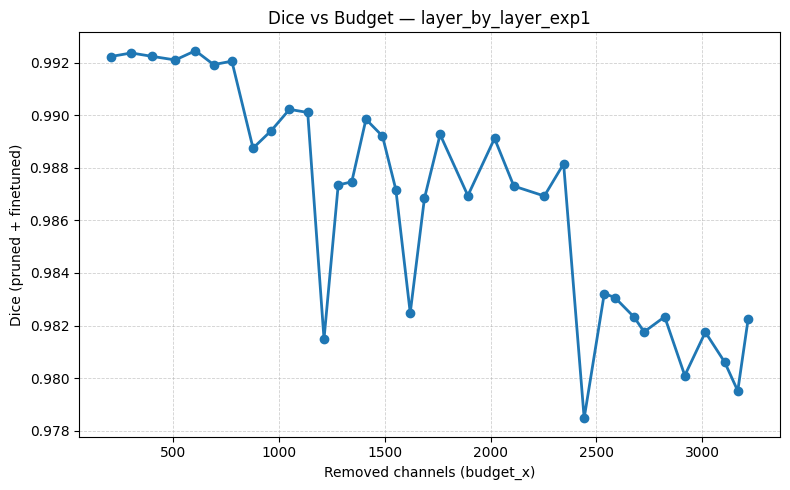

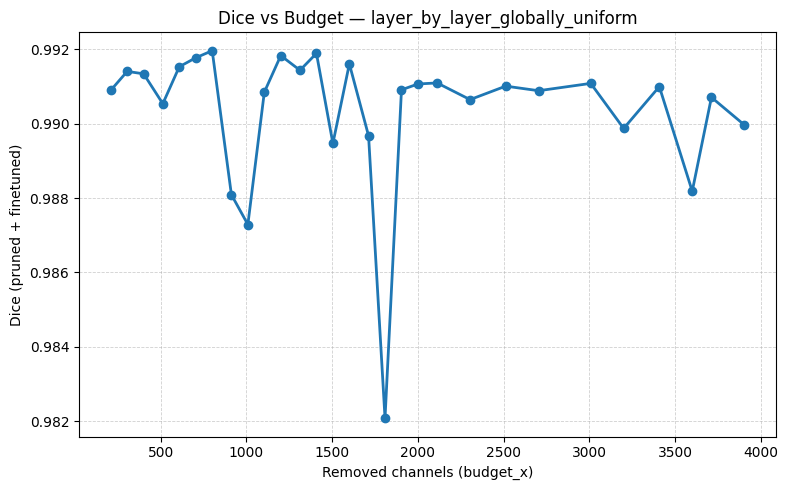

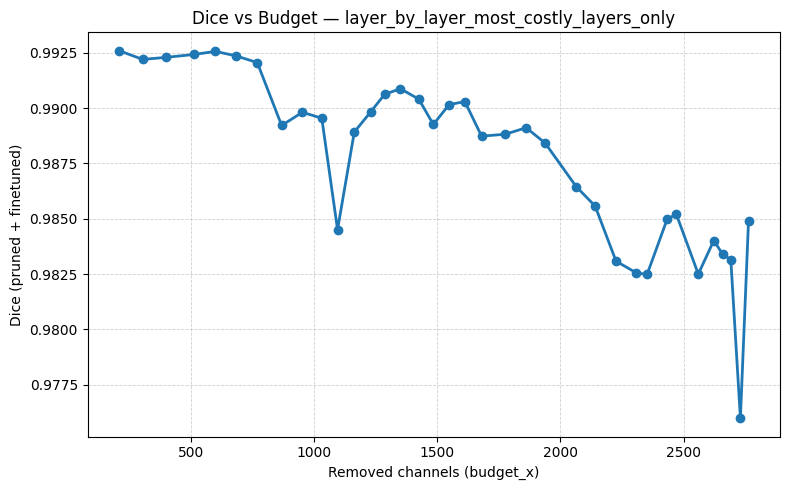

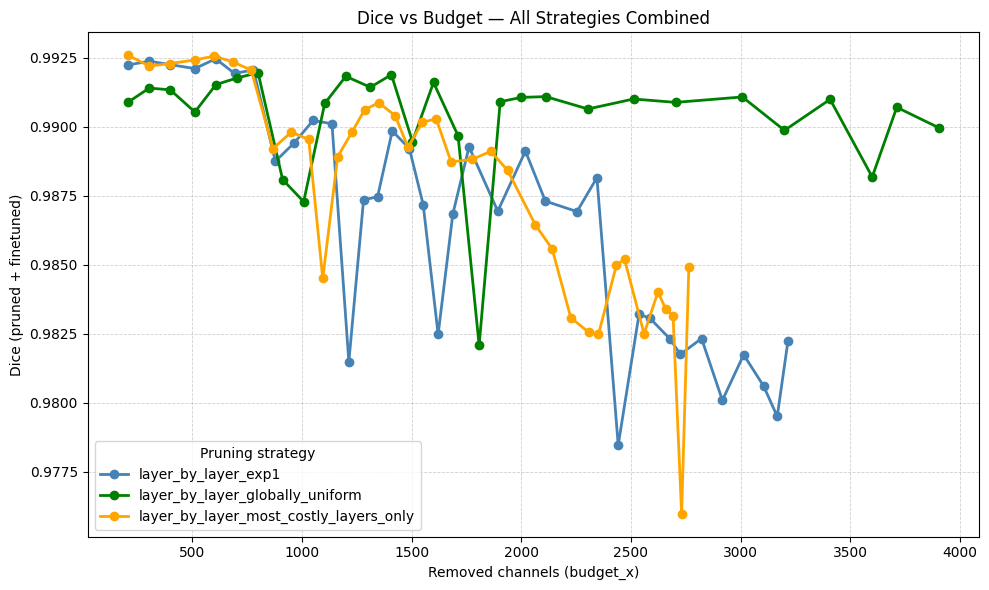

In [7]:
import matplotlib.pyplot as plt

# ── 1. Individual plot per pruning_strategy (separate, clean view) ──────────
strategies = sorted(gplot["pruning_strategy"].unique())

for strat in strategies:
    d = gplot[gplot["pruning_strategy"] == strat].copy().sort_values("budget_x")
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(d["budget_x"], d["dice_pruned"], marker="o", lw=2)
    ax.set_xlabel("Removed channels (budget_x)")
    ax.set_ylabel("Dice (pruned + finetuned)")
    ax.set_title(f"Dice vs Budget — {strat}")
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
    plt.tight_layout()
    plt.show()

# ── 2. Combined comparison: all strategies on one plot ──────────────────────
STRATEGY_COLORS = {
    "layer_by_layer_exp1": "steelblue",
    "global_exp1":         "tomato",
    "layer_by_layer_globally_uniform" : "green",
    "layer_by_layer_most_costly_layers_only" : "orange"
    # add more entries here as you run Exp2, Exp3…
}

fig, ax = plt.subplots(figsize=(10, 6))
for strat in strategies:
    d = gplot[gplot["pruning_strategy"] == strat].copy().sort_values("budget_x")
    color = STRATEGY_COLORS.get(strat)
    ax.plot(d["budget_x"], d["dice_pruned"], marker="o", lw=2,
            label=strat, color=color)
ax.set_xlabel("Removed channels (budget_x)")
ax.set_ylabel("Dice (pruned + finetuned)")
ax.set_title("Dice vs Budget — All Strategies Combined")
ax.legend(title="Pruning strategy")
ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.tight_layout()
plt.show()


In [8]:
# Cell — Theoretical pruning analysis: min keep / max prune per layer, params & FLOPs (min/max)

from __future__ import annotations
import sys, math, os, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# ── Paths ────────────────────────────────────────────────────────────────────
REPO_ROOT = Path("/home/jovyan/cost-based-pruning-layer-by-layer/pruning")
BASELINE_CKPT = Path("/home/jovyan/cost-based-pruning-layer-by-layer/weights/unet_carvana_scale0.5_epoch2.pth")

# config/ sits one level up from pruning/
CONFIG_DIR = REPO_ROOT.parent / "configs"
BASELINE_CHANNELS_TXT = CONFIG_DIR / "model_channels_baseline.txt"

if not BASELINE_CHANNELS_TXT.exists():
    raise FileNotFoundError(f"Cannot find baseline channels file at: {BASELINE_CHANNELS_TXT}")

# ── Add repo to path and import UNet ─────────────────────────────────────────
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from models.unet_flexible import UNet   # or wherever your UNet class lives

# ── FLOPs / analysis flags ───────────────────────────────────────────────────
USE_2X_MACS  = True    # FLOPs = 2 × MACs (standard convention)
EXCLUDE_OUTC = True    # exclude outc.conv from pruning and FLOPs (matches your codebase)

# ── Input resolution ─────────────────────────────────────────────────────────
H = W = 512      

# ── Config ───────────────────────────────────────────────────────────────────
MIN_KEEP_RATIO  = 0.0
MIN_KEEP_ABS    = 1
FRIENDLY_MULT   = 16
FRIENDLY_ROUND  = "up"   # "up" → ceil to multiple; "down" → floor



USE_2X_MACS_  = True
EXCLUDE_OUTC_ = True
_H = _W = 512

# ── Helpers ───────────────────────────────────────────────────────────────────
def ceil_to_mult(x: int, m: int) -> int:
    return int(math.ceil(x / m) * m)

def floor_to_mult(x: int, m: int) -> int:
    return int(math.floor(x / m) * m)

def _safe_load(path: Path):
    try:
        return torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        return torch.load(path, map_location="cpu")

def _extract_sd(obj):
    if isinstance(obj, dict):
        for k in ["state_dict", "model_state_dict", "net", "model"]:
            if k in obj and isinstance(obj[k], dict):
                return obj[k]
        return obj
    raise TypeError(type(obj))

def _strip_module(sd: dict) -> dict:
    if any(k.startswith("module.") for k in sd):
        return {k.replace("module.", "", 1): v for k, v in sd.items()}
    return sd

def _infer_n_classes(sd: dict) -> int:
    if "outc.conv.weight" in sd:
        return int(sd["outc.conv.weight"].shape[0])
    for k, v in sd.items():
        if isinstance(v, torch.Tensor) and v.ndim == 4 and v.shape[2] == 1 and "out" in k.lower():
            return int(v.shape[0])
    raise RuntimeError("Cannot infer n_classes")

# ── Load baseline model ───────────────────────────────────────────────────────
raw  = _safe_load(Path(BASELINE_CKPT))
sd   = _strip_module(_extract_sd(raw))
n_cl = _infer_n_classes(sd)

m_base = UNet(n_channels=3, n_classes=n_cl, f_channels=str(BASELINE_CHANNELS_TXT))
m_base.load_state_dict(sd, strict=True)
m_base.eval()

# ── Group / layer-type helpers ────────────────────────────────────────────────
def _group_of(name: str) -> str:
    if name.startswith("outc."):                            return "other"
    if name.startswith("inc."):                             return "encoder"
    if name.startswith(("down1.", "down2.", "down3.")):     return "encoder"
    if name.startswith("down4."):                           return "bottleneck"
    if name.startswith(("up1.", "up2.", "up3.", "up4.")):   return "decoder"
    return "other"

def _out_channels(mod) -> int:
    if isinstance(mod, nn.Conv2d):
        return int(mod.out_channels)
    g = int(getattr(mod, "groups", 1))
    return int(mod.weight.shape[1] * g)

def _is_unpruned_transpose(name: str, mod: nn.Module) -> bool:
    # up1.up / up2.up / up3.up / up4.up are ConvTranspose2d used only for
    # upsampling — they are reshaped to match adjacent layers but never
    # independently pruned in the codebase.
    return isinstance(mod, nn.ConvTranspose2d) and name.endswith(".up")

# ── Gather conv layers ────────────────────────────────────────────────────────
conv_layers = [
    (nm, mod)
    for nm, mod in m_base.named_modules()
    if isinstance(mod, (nn.Conv2d, nn.ConvTranspose2d))
]

# ── Per-layer min-keep / max-prune ────────────────────────────────────────────
records = []
for nm, mod in conv_layers:
    out_ch          = _out_channels(mod)
    grp             = _group_of(nm)
    is_transpose_up = _is_unpruned_transpose(nm, mod)
    is_outc         = EXCLUDE_OUTC_ and nm.endswith("outc.conv")
    is_prunable     = not (is_transpose_up or is_outc)

    if not is_prunable:
        min_keep  = out_ch
        max_prune = 0
        note      = "unpruned-transpose" if is_transpose_up else "outc"
    else:
        by_ratio = int(math.ceil(MIN_KEEP_RATIO * out_ch))
        raw_keep = max(by_ratio, MIN_KEEP_ABS)
        raw_keep = min(raw_keep, out_ch)

        if FRIENDLY_MULT > 1 and out_ch >= FRIENDLY_MULT:
            if FRIENDLY_ROUND == "up":
                min_keep = ceil_to_mult(raw_keep, FRIENDLY_MULT)
            else:
                min_keep = floor_to_mult(raw_keep, FRIENDLY_MULT)
            min_keep = max(min_keep, FRIENDLY_MULT)
            min_keep = min(min_keep, out_ch)
        else:
            min_keep = raw_keep

        max_prune = out_ch - min_keep
        note      = ""

    records.append({
        "layer_name":      nm,
        "group":           grp,
        "layer_type":      "ConvTranspose2d" if isinstance(mod, nn.ConvTranspose2d) else "Conv2d",
        "is_prunable":     is_prunable,
        "note":            note,
        "out_ch_baseline": out_ch,
        "min_keep_ch":     min_keep,
        "max_prune_ch":    max_prune,
    })

df_layers = pd.DataFrame(records)

# ── Parameter counting ────────────────────────────────────────────────────────
# NOTE: prev_eff_out is only updated for prunable layers.
# Transpose ups are skipped — their output channels are determined by the
# surrounding prunable convs, not by an independent pruning decision.
param_rows   = []
prev_eff_out = 3

for nm, mod in conv_layers:
    row         = df_layers[df_layers["layer_name"] == nm].iloc[0]
    min_keep    = int(row["min_keep_ch"])
    is_prunable = bool(row["is_prunable"])
    g           = int(getattr(mod, "groups", 1))

    if isinstance(mod, nn.Conv2d):
        _, _, Kh, Kw = mod.weight.shape
    else:
        _, _, Kh, Kw = mod.weight.shape

    p_base = int(mod.weight.numel()) + (int(mod.bias.numel()) if mod.bias is not None else 0)

    eff_in = prev_eff_out
    eff_out = min_keep
    p_min  = (eff_out * (eff_in // g) * Kh * Kw) + (min_keep if mod.bias is not None else 0)

    param_rows.append({
        "layer_name":         nm,
        "params_baseline":    p_base,
        "params_min_keep":    p_min,
        "params_removed_max": max(0, p_base - p_min),
    })

    # Only advance the channel tracker for prunable layers.
    # Unpruned transposes do not change the effective channel count
    # seen by the next prunable conv.
    if is_prunable:
        prev_eff_out = min_keep

df_params      = pd.DataFrame(param_rows)
df_theoretical = df_layers.merge(df_params, on="layer_name")

# ── FLOPs via hooks ───────────────────────────────────────────────────────────
def per_layer_macs(net: nn.Module, H: int, W: int, exclude_outc: bool) -> list[tuple[str, int]]:
    net.eval()
    ops, names = [], []
    for nm, m in net.named_modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            ops.append(m); names.append(nm)

    out_hw = {}

    def make_hook(nm_):
        def fn(module, inp, output):
            if isinstance(output, torch.Tensor) and output.ndim == 4:
                out_hw[nm_] = (int(output.shape[2]), int(output.shape[3]))
        return fn

    hooks = [m.register_forward_hook(make_hook(nm)) for nm, m in zip(names, ops)]
    with torch.no_grad():
        net(torch.zeros(1, 3, H, W))
    for h in hooks:
        h.remove()

    result = []
    for nm, m in zip(names, ops):
        if nm not in out_hw:
            continue
        if exclude_outc and nm.endswith("outc.conv"):
            result.append((nm, 0))
            continue
        Hout, Wout = out_hw[nm]
        g = int(getattr(m, "groups", 1))
        if isinstance(m, nn.Conv2d):
            Cout, Cin_g, Kh, Kw = m.weight.shape
        else:
            Cin, Cout_g, Kh, Kw = m.weight.shape
            Cout  = Cout_g * g
            Cin_g = Cin // g
        macs = Hout * Wout * int(Cout) * int(Cin_g) * Kh * Kw
        result.append((nm, int(macs)))
    return result

flops_mult = 2 if USE_2X_MACS_ else 1

# Baseline FLOPs
layer_macs_base = per_layer_macs(m_base, _H, _W, EXCLUDE_OUTC_)
macs_base       = sum(v for _, v in layer_macs_base)
flops_base_g    = macs_base * flops_mult / 1e9
print(f"Baseline FLOPs: {flops_base_g:.4f} GFLOPs  (input {_H}×{_W})")

# Exact min-keep FLOPs: build real UNet with min-keep channel vector
# Only pass channels for prunable layers; transpose ups are excluded from
# the channel file since they are not independently configured.
min_keep_vec = df_theoretical["min_keep_ch"].tolist()
ch_str       = "\n".join(str(c) for c in min_keep_vec)
flops_min_g  = None

with tempfile.NamedTemporaryFile(mode="w", suffix=".txt", delete=False) as tf:
    tf.write(ch_str)
    tmp_ch_path = tf.name

try:
    m_min = UNet(n_channels=3, n_classes=n_cl, f_channels=tmp_ch_path)
    m_min.eval()
    macs_min    = sum(v for _, v in per_layer_macs(m_min, _H, _W, EXCLUDE_OUTC_))
    flops_min_g = macs_min * flops_mult / 1e9
    del m_min
    print(f"Min-keep FLOPs (exact): {flops_min_g:.4f} GFLOPs")
except Exception as e:
    print(f"[WARN] Could not build min-keep model: {e}\n       Falling back to proportional estimate.")
finally:
    os.unlink(tmp_ch_path)

# Estimated min-keep FLOPs: proportional scaling per layer
# Transpose ups are skipped in the ratio chain (same reason as param counting).
layer_macs_min_est = []
prev_base_ch = 3
prev_min_ch  = 3

for (nm, macs_b), row in zip(layer_macs_base, df_theoretical.itertuples()):
    if EXCLUDE_OUTC_ and nm.endswith("outc.conv"):
        layer_macs_min_est.append((nm, 0))
        continue

    is_prunable = bool(row.is_prunable)
    out_b = int(row.out_ch_baseline)
    out_m = int(row.min_keep_ch)

    if is_prunable:
        ratio = (out_m / max(out_b, 1)) * (prev_min_ch / max(prev_base_ch, 1))
        layer_macs_min_est.append((nm, int(macs_b * ratio)))
        prev_base_ch = out_b
        prev_min_ch  = out_m
    else:
        # Transpose up: not pruned, include full baseline MACs
        layer_macs_min_est.append((nm, int(macs_b)))

flops_min_g_est = sum(v for _, v in layer_macs_min_est) * flops_mult / 1e9

# Merge per-layer FLOPs into df_theoretical
macs_base_map = {nm: v for nm, v in layer_macs_base}
macs_min_map  = {nm: v for nm, v in layer_macs_min_est}

df_theoretical["flops_baseline_gf"] = df_theoretical["layer_name"].map(
    {k: v * flops_mult / 1e9 for k, v in macs_base_map.items()}
).fillna(0.0)

df_theoretical["flops_min_keep_gf"] = df_theoretical["layer_name"].map(
    {k: v * flops_mult / 1e9 for k, v in macs_min_map.items()}
).fillna(0.0)

# ── Per-layer percentages ─────────────────────────────────────────────────────
df_theoretical["keep_%"]            = (df_theoretical["min_keep_ch"]        / df_theoretical["out_ch_baseline"]                          * 100).round(1)
df_theoretical["prune_%"]           = (df_theoretical["max_prune_ch"]       / df_theoretical["out_ch_baseline"]                          * 100).round(1)
df_theoretical["params_keep_%"]     = (df_theoretical["params_min_keep"]    / df_theoretical["params_baseline"].replace(0, np.nan)       * 100).round(1)
df_theoretical["params_removed_%"]  = (df_theoretical["params_removed_max"] / df_theoretical["params_baseline"].replace(0, np.nan)       * 100).round(1)
df_theoretical["flops_keep_%"]      = (df_theoretical["flops_min_keep_gf"]  / df_theoretical["flops_baseline_gf"].replace(0, np.nan)     * 100).round(1)
df_theoretical["flops_removed_%"]   = (100 - df_theoretical["flops_keep_%"]).round(1)

# ── Display per-layer table ───────────────────────────────────────────────────
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", "{:.4f}".format)

print("\n" + "="*110)
print("THEORETICAL PRUNING ANALYSIS — per layer")
print(f"  MIN_KEEP_RATIO={MIN_KEEP_RATIO}, MIN_KEEP_ABS={MIN_KEEP_ABS}, "
      f"FRIENDLY_MULT={FRIENDLY_MULT}, FRIENDLY_ROUND='{FRIENDLY_ROUND}'")
print(f"  Input: {_H}×{_W}  |  USE_2X_MACS={USE_2X_MACS_}  |  EXCLUDE_OUTC={EXCLUDE_OUTC_}")
print("="*110)

display(
    df_theoretical[[
        "layer_name", "group", "layer_type", "is_prunable", "note",
        "out_ch_baseline", "min_keep_ch",      "keep_%",
        "max_prune_ch",    "prune_%",
        "params_baseline", "params_min_keep",  "params_keep_%",
        "params_removed_max", "params_removed_%",
        "flops_baseline_gf", "flops_min_keep_gf", "flops_keep_%", "flops_removed_%",
    ]]
)

# ── Summary scalars ───────────────────────────────────────────────────────────
total_params_base    = int(sum(p.numel() for p in m_base.parameters()))
total_params_min_est = int(df_theoretical["params_min_keep"].sum())
total_params_removed = total_params_base - total_params_min_est
pct_params_kept      = 100 * total_params_min_est / total_params_base
pct_params_removed   = 100 * total_params_removed / total_params_base

# Prunable-only channel totals (excludes transpose ups and outc)
prunable_mask        = df_theoretical["is_prunable"]
total_ch_prunable    = int(df_theoretical.loc[prunable_mask, "out_ch_baseline"].sum())
total_ch_max_prune   = int(df_theoretical.loc[prunable_mask, "max_prune_ch"].sum())

print("\n" + "="*90)
print("SUMMARY")
print("="*90)
print(f"  Baseline params            : {total_params_base:>12,}  (100.0%)")
print(f"  Min-keep params (est.)     : {total_params_min_est:>12,}  ({pct_params_kept:.1f}% of original)")
print(f"  Max params removed (est.)  : {total_params_removed:>12,}  ({pct_params_removed:.1f}% of original)")
print()
print(f"  Baseline FLOPs             : {flops_base_g:>10.4f} GFLOPs  (100.0%)")
if flops_min_g is not None:
    pct_flops_kept_exact    = 100 * flops_min_g / flops_base_g
    pct_flops_removed_exact = 100 - pct_flops_kept_exact
    print(f"  Min-keep FLOPs (exact)     : {flops_min_g:>10.4f} GFLOPs  "
          f"({pct_flops_kept_exact:.1f}% of original, -{pct_flops_removed_exact:.1f}%)")
pct_flops_kept_est    = 100 * flops_min_g_est / flops_base_g
pct_flops_removed_est = 100 - pct_flops_kept_est
print(f"  Min-keep FLOPs (est.)      : {flops_min_g_est:>10.4f} GFLOPs  "
      f"({pct_flops_kept_est:.1f}% of original, -{pct_flops_removed_est:.1f}%)")
print()
print(f"  Max channels prunable      : {total_ch_prunable:>8}  (prunable layers only, excl. transpose ups + outc)")
print(f"  Max channels pruned        : {total_ch_max_prune:>8}  "
      f"({100*total_ch_max_prune/total_ch_prunable:.1f}% of prunable channels)")
print("="*90)

# ── Group-level breakdown ─────────────────────────────────────────────────────
grp = df_theoretical.groupby("group").agg(
    layers            = ("layer_name",           "count"),
    ch_baseline       = ("out_ch_baseline",       "sum"),
    ch_min_keep       = ("min_keep_ch",           "sum"),
    ch_max_prune      = ("max_prune_ch",          "sum"),
    params_baseline   = ("params_baseline",       "sum"),
    params_min_keep   = ("params_min_keep",       "sum"),
    params_removed    = ("params_removed_max",    "sum"),
    flops_base_gf     = ("flops_baseline_gf",     "sum"),
    flops_min_gf      = ("flops_min_keep_gf",     "sum"),
).copy()

grp["params_baseline_%"] = (grp["params_baseline"] / grp["params_baseline"].sum()                * 100).round(1)
grp["flops_base_%"]      = (grp["flops_base_gf"]   / grp["flops_base_gf"].sum()                  * 100).round(1)
grp["ch_prune_%"]        = (grp["ch_max_prune"]    / grp["ch_baseline"]                           * 100).round(1)
grp["params_keep_%"]     = (grp["params_min_keep"] / grp["params_baseline"].replace(0, np.nan)    * 100).round(1)
grp["params_remove_%"]   = (grp["params_removed"]  / grp["params_baseline"].replace(0, np.nan)    * 100).round(1)
grp["flops_keep_%"]      = (grp["flops_min_gf"]    / grp["flops_base_gf"].replace(0, np.nan)      * 100).round(1)
grp["flops_remove_%"]    = (100 - grp["flops_keep_%"]).round(1)

print("\nGroup-level breakdown:")
display(grp[[
    "layers",
    "ch_baseline",     "ch_min_keep",       "ch_max_prune",    "ch_prune_%",
    "params_baseline", "params_baseline_%",  "params_min_keep", "params_removed",  "params_keep_%", "params_remove_%",
    "flops_base_gf",   "flops_base_%",       "flops_min_gf",    "flops_keep_%",    "flops_remove_%",
]])

Baseline FLOPs: 436.8452 GFLOPs  (input 512×512)
[WARN] Could not build min-keep model: Given transposed=1, weight of size [512, 16, 2, 2], expected input[1, 16, 32, 32] to have 512 channels, but got 16 channels instead
       Falling back to proportional estimate.

THEORETICAL PRUNING ANALYSIS — per layer
  MIN_KEEP_RATIO=0.0, MIN_KEEP_ABS=1, FRIENDLY_MULT=16, FRIENDLY_ROUND='up'
  Input: 512×512  |  USE_2X_MACS=True  |  EXCLUDE_OUTC=True


,layer_name,group,layer_type,is_prunable,note,out_ch_baseline,min_keep_ch,keep_%,max_prune_ch,prune_%,params_baseline,params_min_keep,params_keep_%,params_removed_max,params_removed_%,flops_baseline_gf,flops_min_keep_gf,flops_keep_%,flops_removed_%
0,inc.double_conv.0,encoder,Conv2d,True,,64,16,25.0000,48,75.0000,1728,432,25.0000,1296,75.0000,0.9060,0.2265,25.0000,75.0000
1,inc.double_conv.3,encoder,Conv2d,True,,64,16,25.0000,48,75.0000,36864,2304,6.2000,34560,93.8000,19.3274,1.2080,6.2000,93.8000
2,down1.maxpool_conv.1.double_conv.0,encoder,Conv2d,True,,128,16,12.5000,112,87.5000,73728,2304,3.1000,71424,96.9000,9.6637,0.3020,3.1000,96.9000
3,down1.maxpool_conv.1.double_conv.3,encoder,Conv2d,True,,128,16,12.5000,112,87.5000,147456,2304,1.6000,145152,98.4000,19.3274,0.3020,1.6000,98.4000
4,down2.maxpool_conv.1.double_conv.0,encoder,Conv2d,True,,256,16,6.2000,240,93.8000,294912,2304,0.8000,292608,99.2000,9.6637,0.0755,0.8000,99.2000
5,down2.maxpool_conv.1.double_conv.3,encoder,Conv2d,True,,256,16,6.2000,240,93.8000,589824,2304,0.4000,587520,99.6000,19.3274,0.0755,0.4000,99.6000
6,down3.maxpool_conv.1.double_conv.0,encoder,Conv2d,True,,512,16,3.1000,496,96.9000,1179648,2304,0.2000,1177344,99.8000,9.6637,0.0189,0.2000,99.8000
7,down3.maxpool_conv.1.double_conv.3,encoder,Conv2d,True,,512,16,3.1000,496,96.9000,2359296,2304,0.1000,2356992,99.9000,19.3274,0.0189,0.1000,99.9000
8,down4.maxpool_conv.1.double_conv.0,bottleneck,Conv2d,True,,1024,16,1.6000,1008,98.4000,4718592,2304,0.0000,4716288,100.0000,9.6637,0.0047,0.0000,100.0000
9,down4.maxpool_conv.1.double_conv.3,bottleneck,Conv2d,True,,1024,16,1.6000,1008,98.4000,9437184,2304,0.0000,9434880,100.0000,19.3274,0.0047,0.0000,100.0000



SUMMARY
  Baseline params            :   31,037,698  (100.0%)
  Min-keep params (est.)     :      102,034  (0.3% of original)
  Max params removed (est.)  :   30,935,664  (99.7% of original)

  Baseline FLOPs             :   436.8452 GFLOPs  (100.0%)
  Min-keep FLOPs (est.)      :    74.1647 GFLOPs  (17.0% of original, -83.0%)

  Max channels prunable      :     5888  (prunable layers only, excl. transpose ups + outc)
  Max channels pruned        :     5600  (95.1% of prunable channels)

Group-level breakdown:


,layers,ch_baseline,ch_min_keep,ch_max_prune,ch_prune_%,params_baseline,params_baseline_%,params_min_keep,params_removed,params_keep_%,params_remove_%,flops_base_gf,flops_base_%,flops_min_gf,flops_keep_%,flops_remove_%
group,,,,,,,,,,,,,,,,
bottleneck,2,2048,32,2016,98.4000,14155776,45.6000,4608,14151168,0.0000,100.0000,28.9910,6.6000,0.0094,0.0000,100.0000
decoder,12,2880,1088,1792,62.2000,12186560,39.3000,80832,12105728,0.7000,99.3000,300.6477,68.8000,71.9281,23.9000,76.1000
encoder,8,1920,128,1792,93.3000,4683456,15.1000,16560,4666896,0.4000,99.6000,107.2064,24.5000,2.2272,2.1000,97.9000
other,1,2,2,0,0.0000,130,0.0000,34,96,26.2000,73.8000,0.0000,0.0000,0.0000,NaN,NaN


In [9]:
# ── Summary scalars ───────────────────────────────────────────────────────────
total_params_base    = int(sum(p.numel() for p in m_base.parameters()))
total_params_min_est = int(df_theoretical["params_min_keep"].sum())
total_params_removed = total_params_base - total_params_min_est
pct_params_kept      = 100 * total_params_min_est / total_params_base
pct_params_removed   = 100 * total_params_removed / total_params_base

# Prunable-only channel totals (excludes transpose ups and outc)
prunable_mask         = df_theoretical["is_prunable"]
unprunable_mask       = ~prunable_mask

# ── Channel counts ────────────────────────────────────────────────────────────
total_ch_all          = int(df_theoretical["out_ch_baseline"].sum())
total_ch_unprunable   = int(df_theoretical.loc[unprunable_mask, "out_ch_baseline"].sum())
total_ch_prunable     = int(df_theoretical.loc[prunable_mask,   "out_ch_baseline"].sum())
total_ch_max_prune    = int(df_theoretical.loc[prunable_mask,   "max_prune_ch"].sum())
total_ch_min_keep     = int(df_theoretical.loc[prunable_mask,   "min_keep_ch"].sum())

# ── Parameter counts ──────────────────────────────────────────────────────────
total_params_unprunable = int(df_theoretical.loc[unprunable_mask, "params_baseline"].sum())
total_params_prunable   = int(df_theoretical.loc[prunable_mask,   "params_baseline"].sum())
total_params_prunable_kept    = int(df_theoretical.loc[prunable_mask, "params_min_keep"].sum())
total_params_prunable_removed = int(df_theoretical.loc[prunable_mask, "params_removed_max"].sum())

pct_ch_prunable       = 100 * total_ch_prunable   / total_ch_all
pct_ch_unprunable     = 100 * total_ch_unprunable / total_ch_all
pct_ch_max_prune      = 100 * total_ch_max_prune  / total_ch_prunable
pct_ch_min_keep       = 100 * total_ch_min_keep   / total_ch_prunable

pct_params_prunable   = 100 * total_params_prunable   / total_params_base
pct_params_unprunable = 100 * total_params_unprunable / total_params_base
pct_params_prunable_removed = 100 * total_params_prunable_removed / total_params_prunable
pct_params_prunable_kept    = 100 * total_params_prunable_kept    / total_params_prunable

print("\n" + "="*90)
print("SUMMARY")
print("="*90)

print("\n── CHANNELS ─────────────────────────────────────────────────────────────────")
print(f"  Total channels (all layers)     : {total_ch_all:>8,}  (100.0%)")
print(f"  Prunable channels               : {total_ch_prunable:>8,}  ({pct_ch_prunable:.1f}% of total)")
print(f"  Unprunable channels             : {total_ch_unprunable:>8,}  ({pct_ch_unprunable:.1f}% of total)")
print(f"    → of which fixed (transpose ups + outc)")
print(f"  Min channels kept after max pruning : {total_ch_min_keep:>8,}  ({pct_ch_min_keep:.1f}% of prunable channels)")
print(f"  Max channels removable          : {total_ch_max_prune:>8,}  ({pct_ch_max_prune:.1f}% of prunable channels)")

print("\n── PARAMETERS ───────────────────────────────────────────────────────────────")
print(f"  Total params (all layers)       : {total_params_base:>12,}  (100.0%)")
print(f"  Prunable-layer params           : {total_params_prunable:>12,}  ({pct_params_prunable:.1f}% of total)")
print(f"  Unprunable-layer params         : {total_params_unprunable:>12,}  ({pct_params_unprunable:.1f}% of total)")
print(f"  Max params removable (est.)     : {total_params_prunable_removed:>12,}  ({pct_params_prunable_removed:.1f}% of prunable params)")
print(f"  Min params kept in prunable     : {total_params_prunable_kept:>12,}  ({pct_params_prunable_kept:.1f}% of prunable params)")
print(f"  Min-keep params total (est.)    : {total_params_min_est:>12,}  ({pct_params_kept:.1f}% of all params)")
print(f"  Max params removed total (est.) : {total_params_removed:>12,}  ({pct_params_removed:.1f}% of all params)")

print("\n── FLOPs ────────────────────────────────────────────────────────────────────")
print(f"  Baseline FLOPs                  : {flops_base_g:>10.4f} GFLOPs  (100.0%)")
if flops_min_g is not None:
    pct_flops_kept_exact    = 100 * flops_min_g / flops_base_g
    pct_flops_removed_exact = 100 - pct_flops_kept_exact
    print(f"  Min-keep FLOPs (exact)          : {flops_min_g:>10.4f} GFLOPs  "
          f"({pct_flops_kept_exact:.1f}% kept, -{pct_flops_removed_exact:.1f}% removed)")
pct_flops_kept_est    = 100 * flops_min_g_est / flops_base_g
pct_flops_removed_est = 100 - pct_flops_kept_est
print(f"  Min-keep FLOPs (est.)           : {flops_min_g_est:>10.4f} GFLOPs  "
      f"({pct_flops_kept_est:.1f}% kept, -{pct_flops_removed_est:.1f}% removed)")

print("="*90)


SUMMARY

── CHANNELS ─────────────────────────────────────────────────────────────────
  Total channels (all layers)     :    6,850  (100.0%)
  Prunable channels               :    5,888  (86.0% of total)
  Unprunable channels             :      962  (14.0% of total)
    → of which fixed (transpose ups + outc)
  Min channels kept after max pruning :      288  (4.9% of prunable channels)
  Max channels removable          :    5,600  (95.1% of prunable channels)

── PARAMETERS ───────────────────────────────────────────────────────────────
  Total params (all layers)       :   31,037,698  (100.0%)
  Prunable-layer params           :   28,239,552  (91.0% of total)
  Unprunable-layer params         :    2,786,370  (9.0% of total)
  Max params removable (est.)     :   28,199,952  (99.9% of prunable params)
  Min params kept in prunable     :       39,600  (0.1% of prunable params)
  Min-keep params total (est.)    :      102,034  (0.3% of all params)
  Max params removed total (est.) :   3

Baseline FLOPs (recomputed): 436.8452 GFLOPs
Recomputing FLOPs from pruned channel files...
Done.
      pruning_strategy  budget_x  flops_g_pruned_recomputed  \
0  layer_by_layer_exp1       208                   365.6046   
1  layer_by_layer_exp1       304                   336.5898   
2  layer_by_layer_exp1       400                   309.5938   
3  layer_by_layer_exp1       512                   280.2569   
4  layer_by_layer_exp1       607                   258.2863   
5  layer_by_layer_exp1       693                   241.8804   
6  layer_by_layer_exp1       779                   228.9604   
7  layer_by_layer_exp1       879                   213.9364   
8  layer_by_layer_exp1       965                   199.3328   
9  layer_by_layer_exp1      1051                   187.6603   

   flops_reduction_pct_recomputed  
0                         16.3080  
1                         22.9499  
2                         29.1296  
3                         35.8453  
4                         40

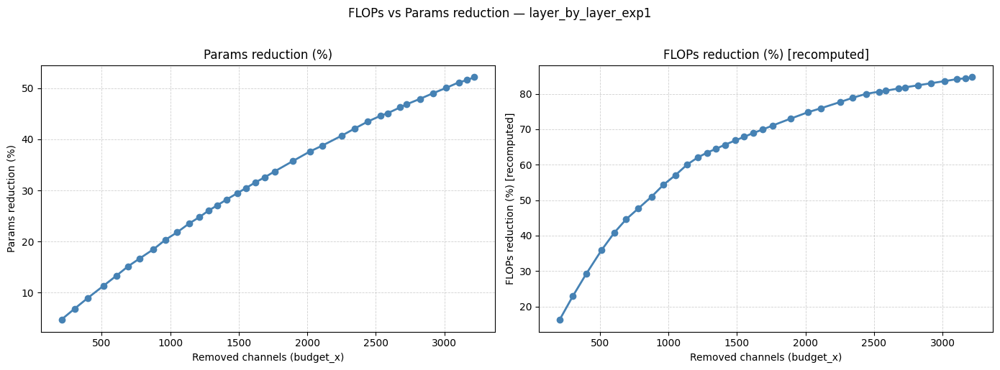

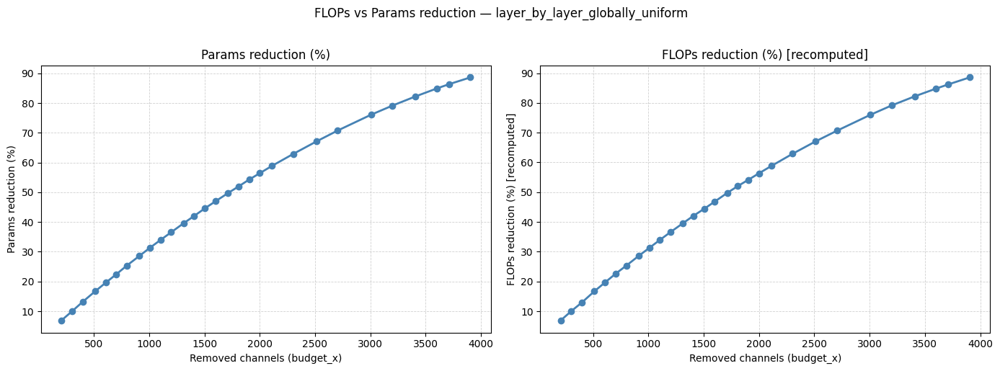

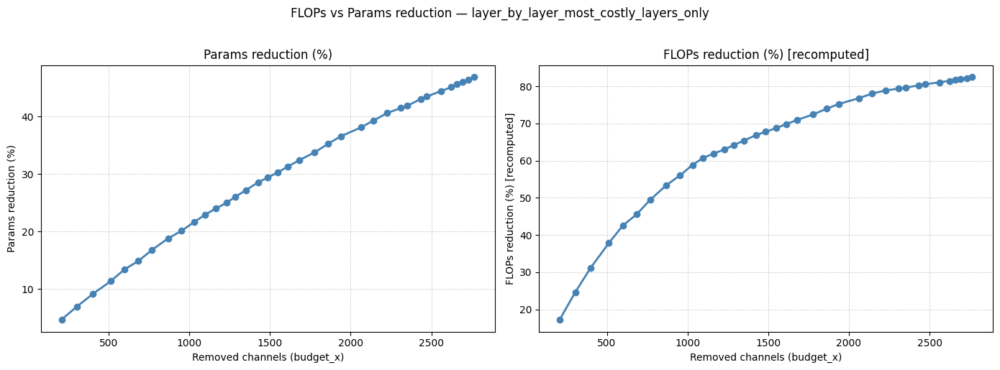

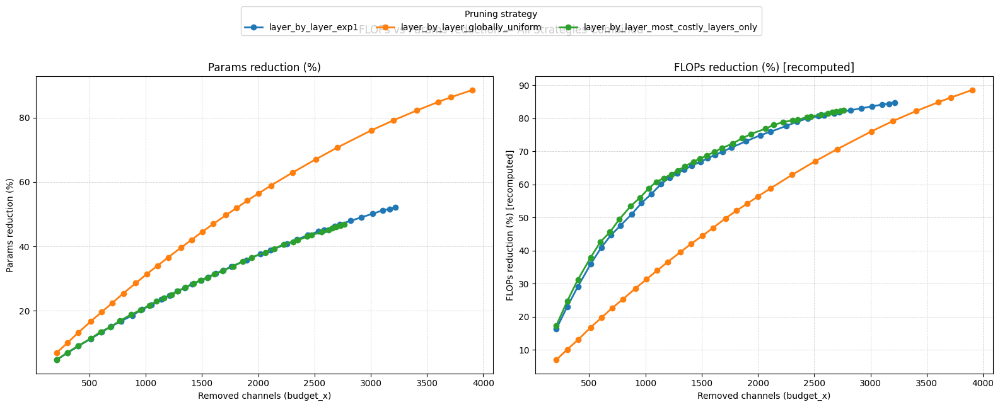

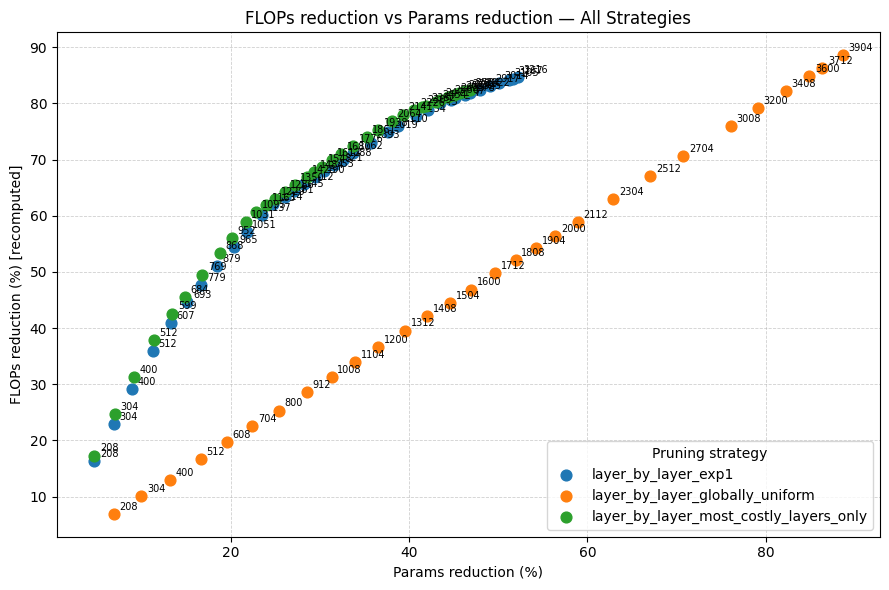

In [10]:
import matplotlib.pyplot as plt
import tempfile, os
import torch
import torch.nn as nn

# ── Recompute FLOPs for each run from the saved pruned channel txt ────────────
# This mirrors the theoretical cell's approach: build a real UNet with the
# pruned channels and measure MACs via hooks.

USE_2X_MACS  = True
EXCLUDE_OUTC = True
_H = _W = 512

def per_layer_macs(net, H, W, exclude_outc):
    net.eval()
    ops, names = [], []
    for nm, m in net.named_modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            ops.append(m); names.append(nm)
    out_hw = {}
    def make_hook(nm_):
        def fn(module, inp, output):
            if isinstance(output, torch.Tensor) and output.ndim == 4:
                out_hw[nm_] = (int(output.shape[2]), int(output.shape[3]))
        return fn
    hooks = [m.register_forward_hook(make_hook(nm)) for nm, m in zip(names, ops)]
    with torch.no_grad():
        net(torch.zeros(1, 3, H, W))
    for h in hooks:
        h.remove()
    result = []
    for nm, m in zip(names, ops):
        if nm not in out_hw:
            continue
        if exclude_outc and nm.endswith("outc.conv"):
            result.append((nm, 0))
            continue
        Hout, Wout = out_hw[nm]
        g = int(getattr(m, "groups", 1))
        if isinstance(m, nn.Conv2d):
            Cout, Cin_g, Kh, Kw = m.weight.shape
        else:
            Cin, Cout_g, Kh, Kw = m.weight.shape
            Cout  = Cout_g * g
            Cin_g = Cin // g
        macs = Hout * Wout * int(Cout) * int(Cin_g) * Kh * Kw
        result.append((nm, int(macs)))
    return result

flops_mult = 2 if USE_2X_MACS else 1

# Compute baseline FLOPs once
m_base_tmp = UNet(n_channels=3, n_classes=2, f_channels=str(BASELINE_CHANNELS_TXT))
m_base_tmp.eval()
baseline_flops_g = sum(v for _, v in per_layer_macs(m_base_tmp, _H, _W, EXCLUDE_OUTC)) * flops_mult / 1e9
del m_base_tmp
print(f"Baseline FLOPs (recomputed): {baseline_flops_g:.4f} GFLOPs")

# Recompute FLOPs for each run
def _recompute_flops_g(log_path: str) -> float:
    """Given a log path, find the pruned_channels.txt and recompute FLOPs."""
    log_dir = str(Path(log_path).parent)
    ch_txt  = os.path.join(log_dir, "pruned_channels.txt")
    if not os.path.exists(ch_txt):
        return np.nan
    try:
        net = UNet(n_channels=3, n_classes=2, f_channels=ch_txt)
        net.eval()
        macs = sum(v for _, v in per_layer_macs(net, _H, _W, EXCLUDE_OUTC))
        del net
        return macs * flops_mult / 1e9
    except Exception as e:
        print(f"[WARN] FLOPs recompute failed for {log_path}: {e}")
        return np.nan

print("Recomputing FLOPs from pruned channel files...")
gplot = gdf.dropna(subset=[c for c in CRIT if c in gdf.columns]).copy()
gplot["flops_g_pruned_recomputed"] = gplot["log_path"].apply(_recompute_flops_g)
gplot["flops_g_baseline_recomputed"] = baseline_flops_g
gplot["flops_reduction_pct_recomputed"] = 100 * (
    1 - gplot["flops_g_pruned_recomputed"] / baseline_flops_g
)
print("Done.")
print(gplot[["pruning_strategy", "budget_x", "flops_g_pruned_recomputed", "flops_reduction_pct_recomputed"]].head(10))

# ── Plot setup ────────────────────────────────────────────────────────────────
STRATEGY_COLORS = {
    "global_proportional":          "steelblue",
    "global_cost_based":            "tomato",
    "global_fpgm_proportional":     "green",
    "global_fpgm_most_costly_only": "orange",
}
strategies = sorted(gplot["pruning_strategy"].unique())

# ── 1. Per-strategy: FLOPs reduction % vs Params reduction % ─────────────────
for strat in strategies:
    d = gplot[gplot["pruning_strategy"] == strat].copy().sort_values("budget_x")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"FLOPs vs Params reduction — {strat}", y=1.02)

    ax = axes[0]
    ax.plot(d["budget_x"], d["params_reduction_pct"], marker="o", lw=2,
            color=STRATEGY_COLORS.get(strat, "steelblue"))
    ax.set_xlabel("Removed channels (budget_x)")
    ax.set_ylabel("Params reduction (%)")
    ax.set_title("Params reduction (%)")
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

    ax = axes[1]
    ax.plot(d["budget_x"], d["flops_reduction_pct_recomputed"], marker="o", lw=2,
            color=STRATEGY_COLORS.get(strat, "steelblue"))
    ax.set_xlabel("Removed channels (budget_x)")
    ax.set_ylabel("FLOPs reduction (%) [recomputed]")
    ax.set_title("FLOPs reduction (%) [recomputed]")
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

    plt.tight_layout()
    plt.show()

# ── 2. Combined: all strategies, FLOPs vs Params ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("FLOPs vs Params reduction — All Strategies Combined", y=1.02)

for strat in strategies:
    d = gplot[gplot["pruning_strategy"] == strat].copy().sort_values("budget_x")
    color = STRATEGY_COLORS.get(strat)

    axes[0].plot(d["budget_x"], d["params_reduction_pct"], marker="o", lw=2,
                 label=strat, color=color)
    axes[1].plot(d["budget_x"], d["flops_reduction_pct_recomputed"], marker="o", lw=2,
                 label=strat, color=color)

axes[0].set_xlabel("Removed channels (budget_x)")
axes[0].set_ylabel("Params reduction (%)")
axes[0].set_title("Params reduction (%)")
axes[0].grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

axes[1].set_xlabel("Removed channels (budget_x)")
axes[1].set_ylabel("FLOPs reduction (%) [recomputed]")
axes[1].set_title("FLOPs reduction (%) [recomputed]")
axes[1].grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center",
               ncol=min(len(labels), 6), bbox_to_anchor=(0.5, 1.08),
               title="Pruning strategy")
plt.tight_layout()
plt.show()

# ── 3. FLOPs reduction vs Params reduction scatter (trade-off view) ──────────
fig, ax = plt.subplots(figsize=(9, 6))
for strat in strategies:
    d = gplot[gplot["pruning_strategy"] == strat].copy()
    ax.scatter(d["params_reduction_pct"], d["flops_reduction_pct_recomputed"],
               label=strat, color=STRATEGY_COLORS.get(strat), s=60, zorder=3)
    for _, row in d.iterrows():
        ax.annotate(f"{int(row['budget_x'])}",
                    (row["params_reduction_pct"], row["flops_reduction_pct_recomputed"]),
                    fontsize=7, textcoords="offset points", xytext=(4, 3))
ax.set_xlabel("Params reduction (%)")
ax.set_ylabel("FLOPs reduction (%) [recomputed]")
ax.set_title("FLOPs reduction vs Params reduction — All Strategies")
ax.legend(title="Pruning strategy")
ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.tight_layout()
plt.show()

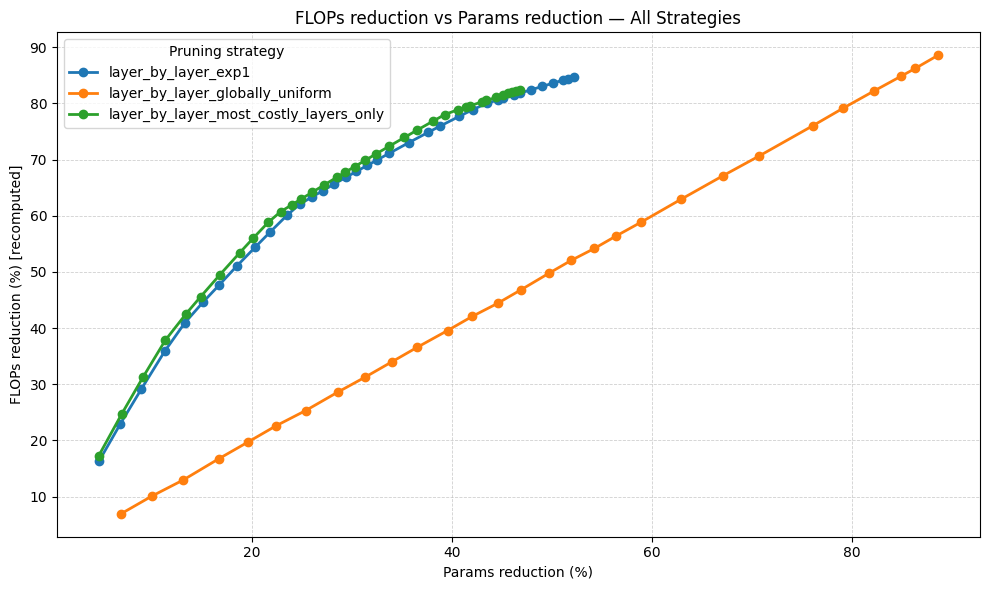

In [11]:
# ── FLOPs reduction vs Params reduction % — all strategies on one graph ──────
fig, ax = plt.subplots(figsize=(10, 6))

for strat in strategies:
    d = gplot[gplot["pruning_strategy"] == strat].copy().sort_values("params_reduction_pct")
    ax.plot(d["params_reduction_pct"], d["flops_reduction_pct_recomputed"],
            marker="o", lw=2, label=strat, color=STRATEGY_COLORS.get(strat))

ax.set_xlabel("Params reduction (%)")
ax.set_ylabel("FLOPs reduction (%) [recomputed]")
ax.set_title("FLOPs reduction vs Params reduction — All Strategies")
ax.legend(title="Pruning strategy")
ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.tight_layout()
plt.show()

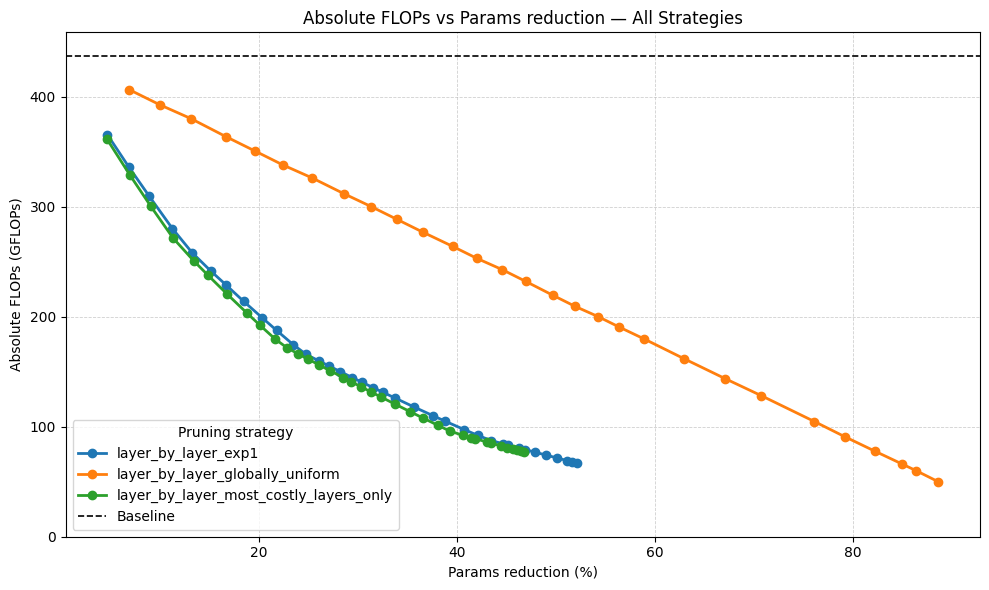

In [12]:
# ── Absolute FLOPs vs Params reduction % — all strategies on one graph ────────
fig, ax = plt.subplots(figsize=(10, 6))

for strat in strategies:
    d = gplot[gplot["pruning_strategy"] == strat].copy().sort_values("params_reduction_pct")
    ax.plot(d["params_reduction_pct"], d["flops_g_pruned_recomputed"],
            marker="o", lw=2, label=strat, color=STRATEGY_COLORS.get(strat))

# Baseline reference line
ax.axhline(y=baseline_flops_g, color="black", linestyle="--", linewidth=1.2, label="Baseline")

ax.set_xlabel("Params reduction (%)")
ax.set_ylabel("Absolute FLOPs (GFLOPs)")
ax.set_title("Absolute FLOPs vs Params reduction — All Strategies")
ax.set_ylim(0, baseline_flops_g * 1.05)
ax.legend(title="Pruning strategy")
ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.tight_layout()
plt.show()

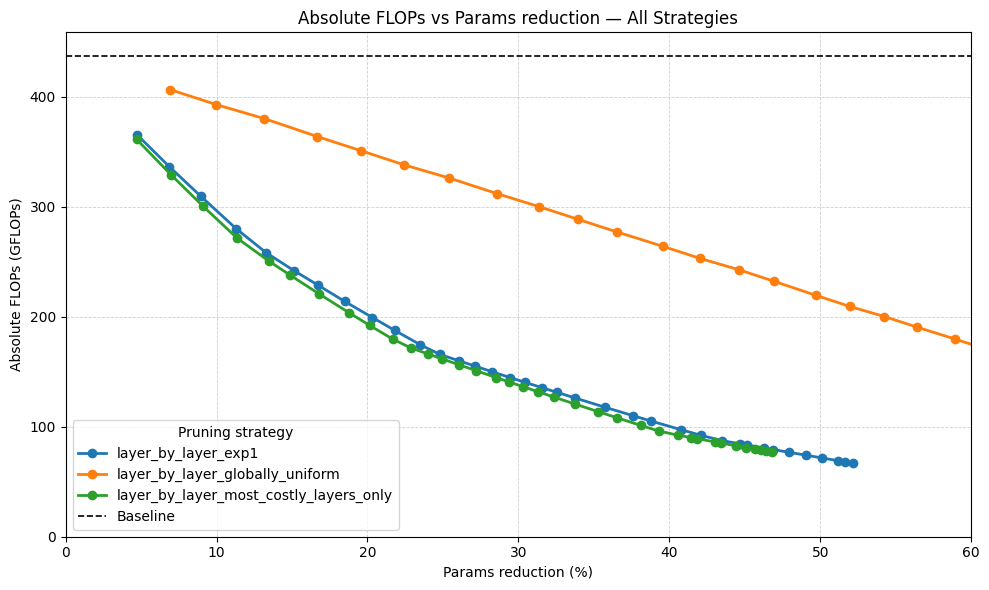

In [13]:
# ── Absolute FLOPs vs Params reduction % — all strategies on one graph ────────
fig, ax = plt.subplots(figsize=(10, 6))

for strat in strategies:
    d = gplot[gplot["pruning_strategy"] == strat].copy().sort_values("params_reduction_pct")
    ax.plot(d["params_reduction_pct"], d["flops_g_pruned_recomputed"],
            marker="o", lw=2, label=strat, color=STRATEGY_COLORS.get(strat))

# Baseline reference line
ax.axhline(y=baseline_flops_g, color="black", linestyle="--", linewidth=1.2, label="Baseline")

ax.set_xlabel("Params reduction (%)")
ax.set_ylabel("Absolute FLOPs (GFLOPs)")
ax.set_title("Absolute FLOPs vs Params reduction — All Strategies")
ax.set_ylim(0, baseline_flops_g * 1.05)
ax.set_xlim(0, 60)
ax.legend(title="Pruning strategy")
ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.tight_layout()
plt.show()

Layers tracked: 22
Baseline total FLOPs : 436.8452 GFLOPs
Baseline total Params: 31,025,792
Recomputing per-layer stats for all runs...
Done.
df_layer_plot shape: (2222, 9)


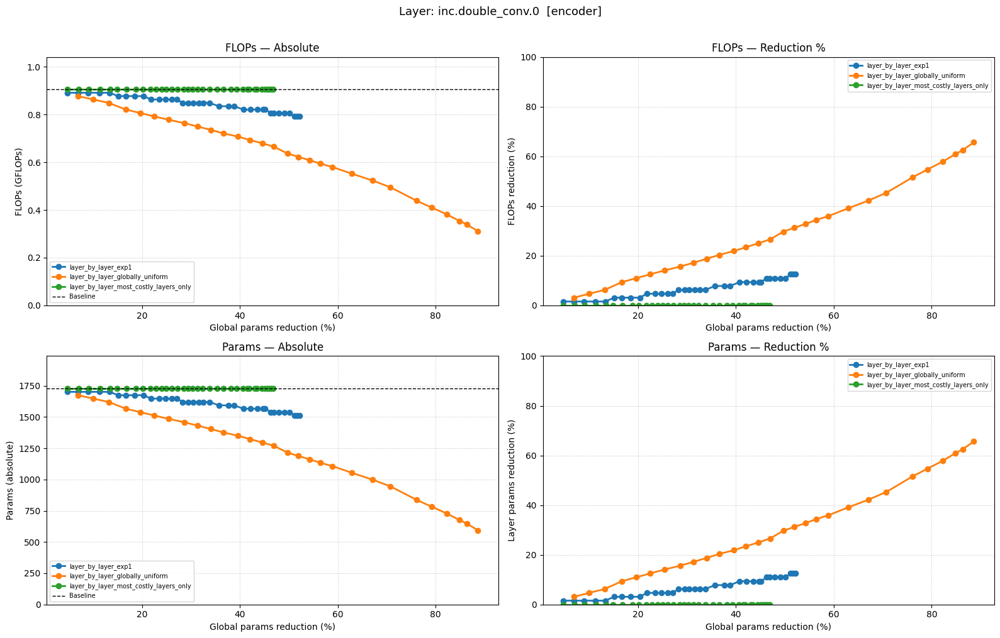

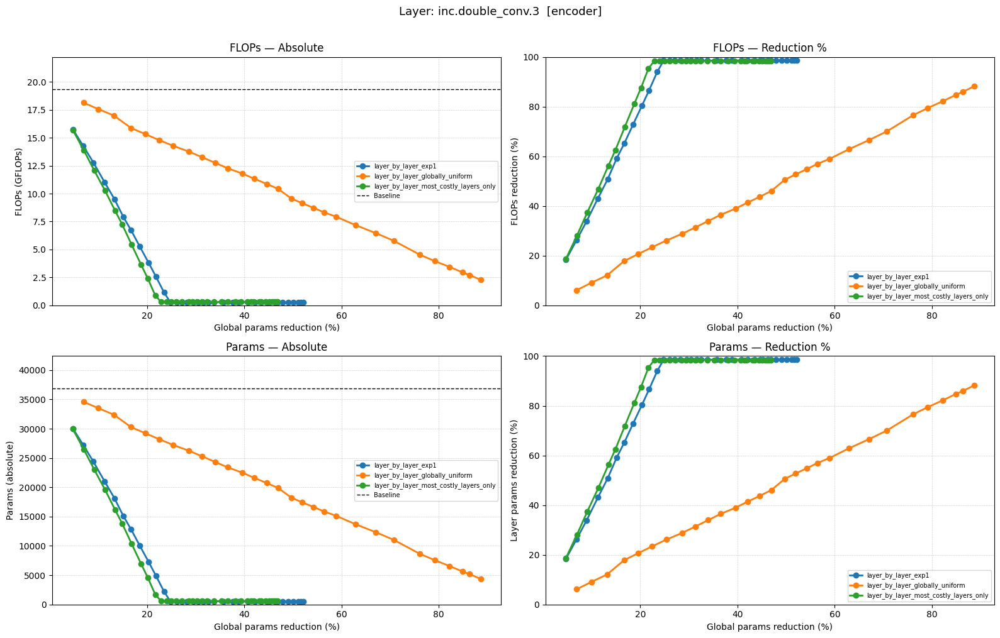

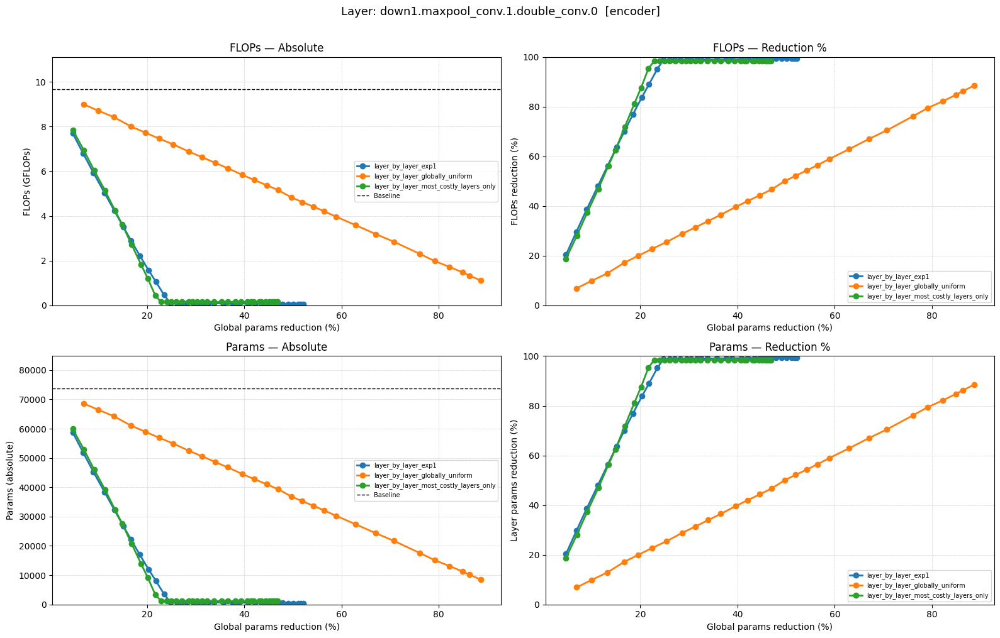

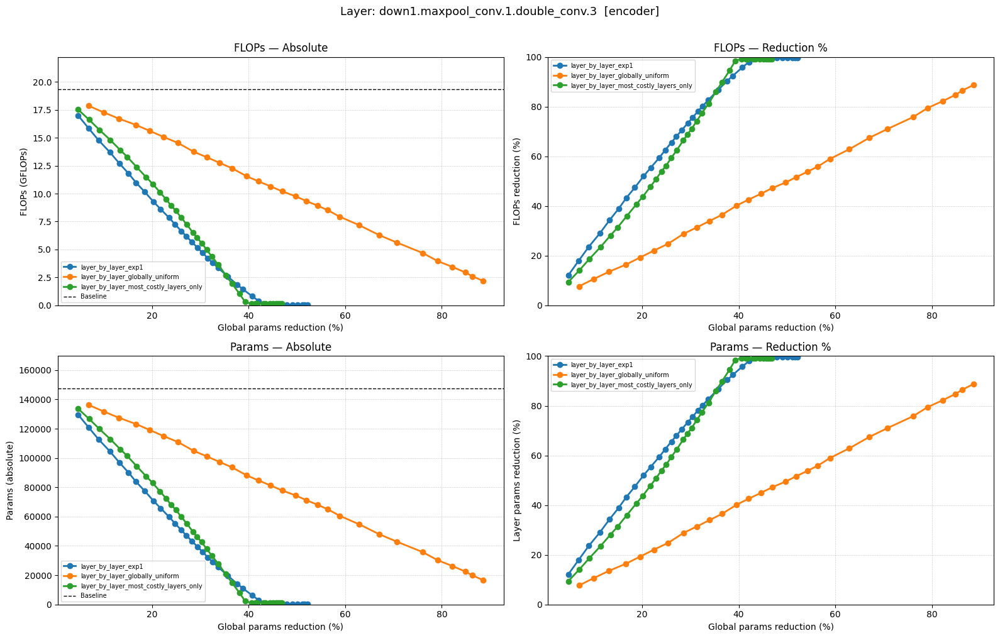

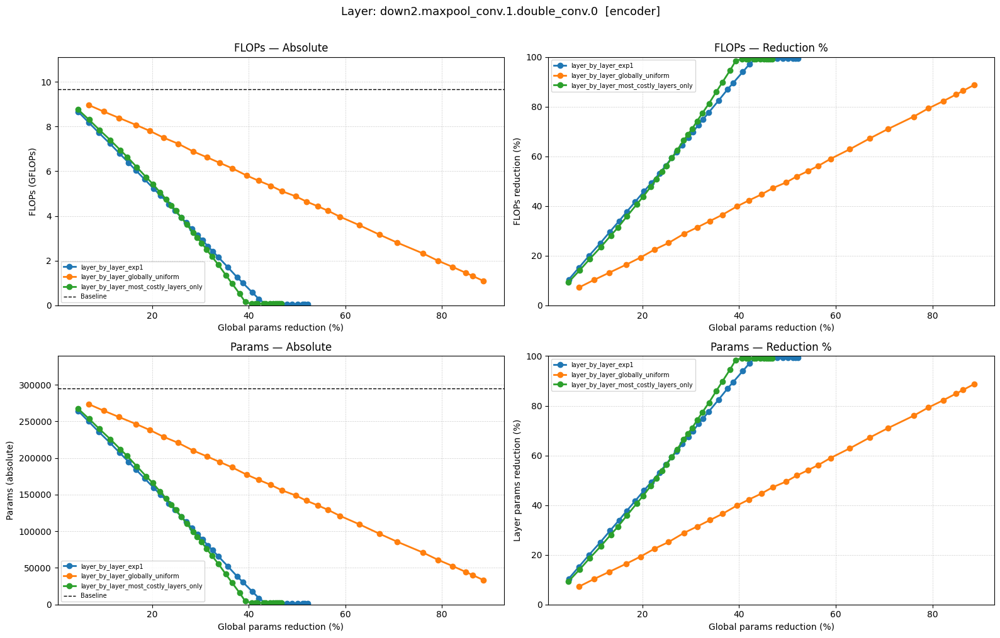

...

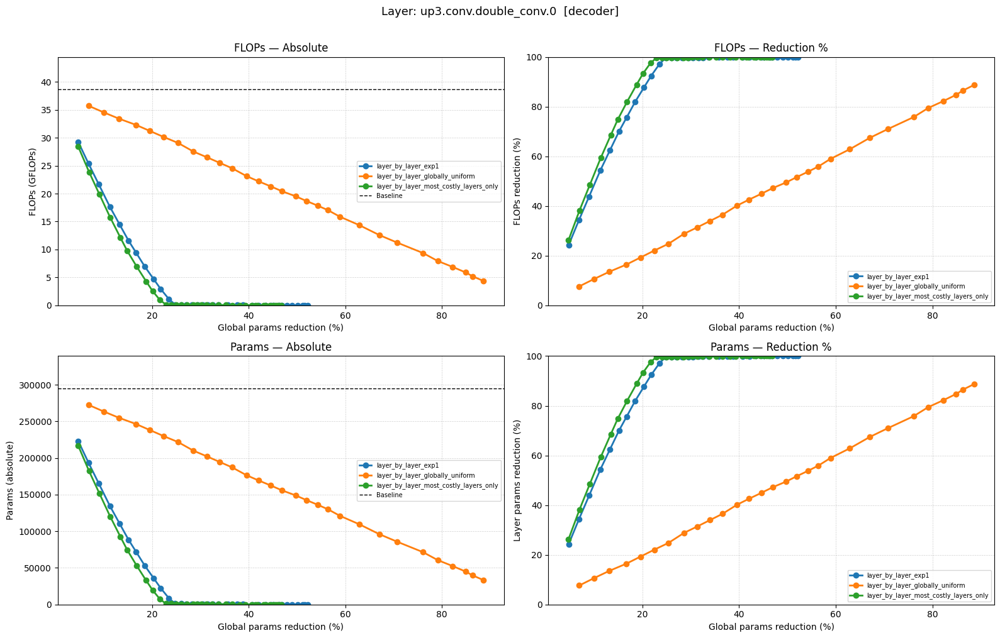

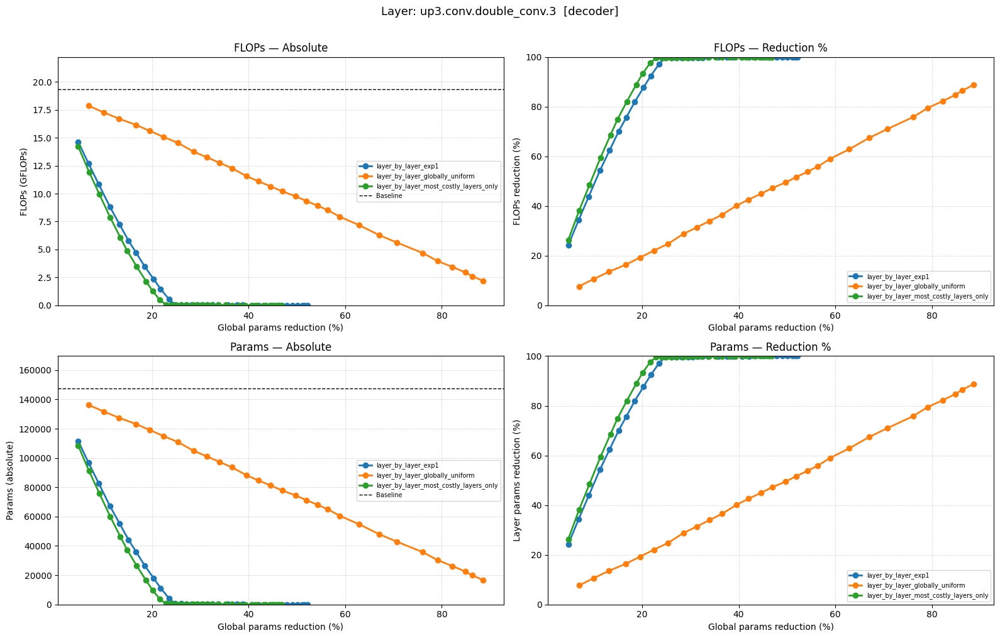

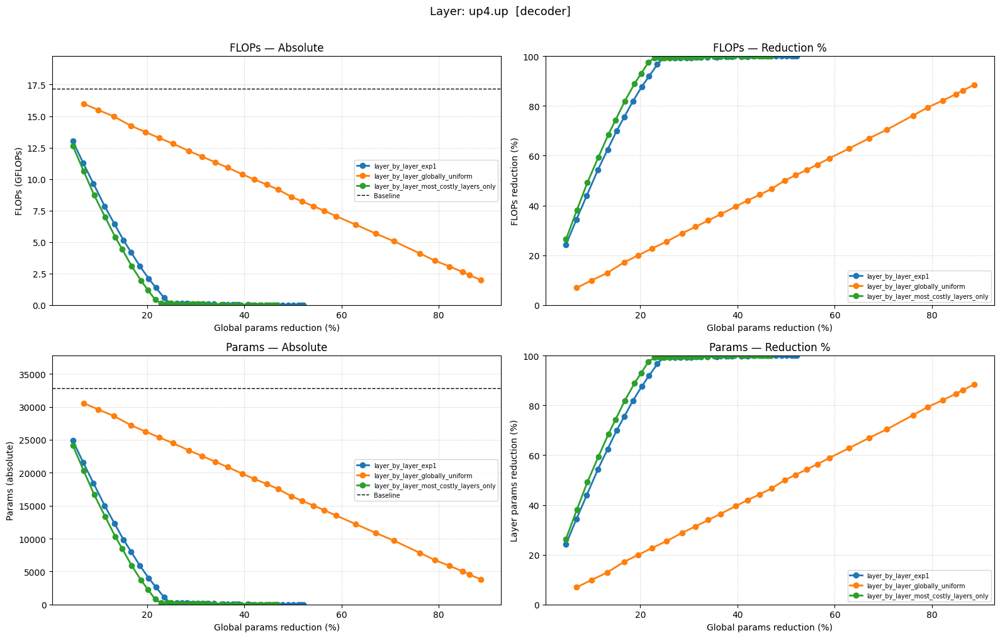

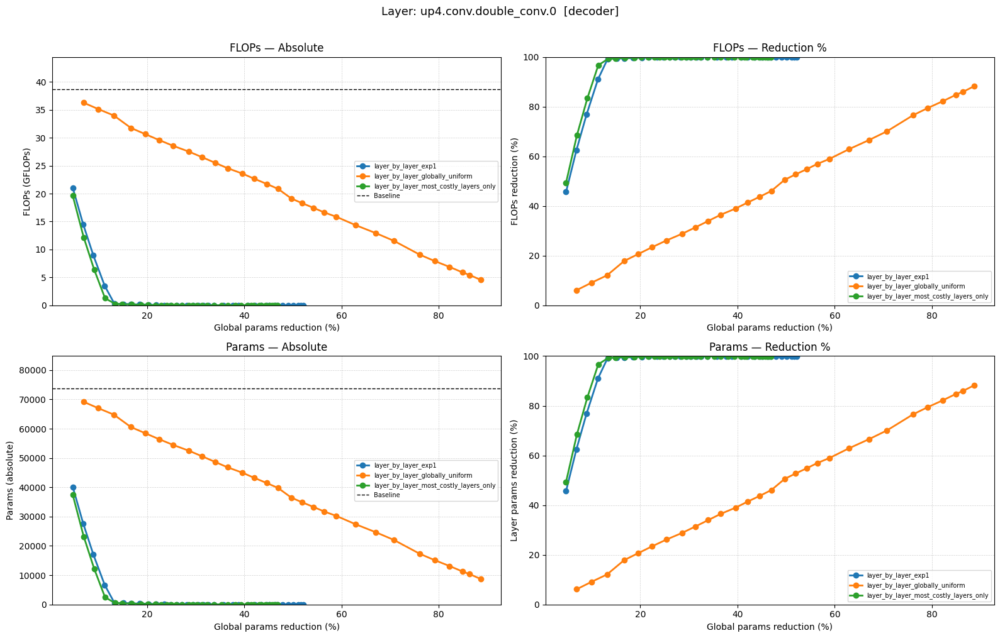

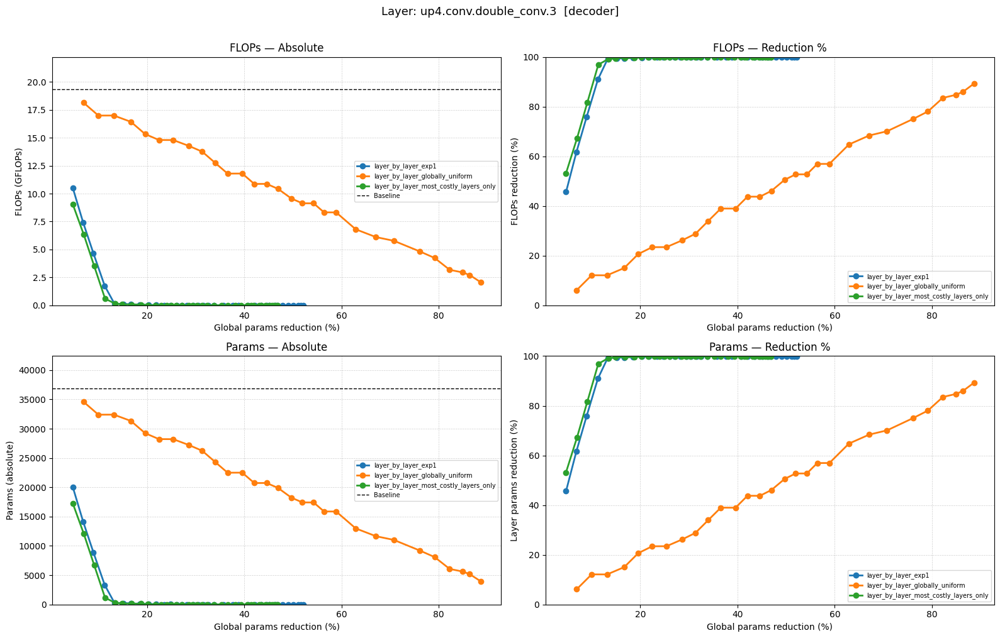

In [14]:
# ── Per-layer FLOPs and Params vs Global Params reduction % ──────────────────
import matplotlib.pyplot as plt
import torch.nn as nn
import numpy as np
from pathlib import Path
import os

# ── Recompute per-layer FLOPs and Params for each run ────────────────────────

def per_layer_macs_and_params(net, H, W, exclude_outc):
    """Returns dict: layer_name -> (macs, params)"""
    net.eval()
    ops, names = [], []
    for nm, m in net.named_modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            ops.append(m); names.append(nm)

    out_hw = {}
    def make_hook(nm_):
        def fn(module, inp, output):
            if isinstance(output, torch.Tensor) and output.ndim == 4:
                out_hw[nm_] = (int(output.shape[2]), int(output.shape[3]))
        return fn
    hooks = [m.register_forward_hook(make_hook(nm)) for nm, m in zip(names, ops)]
    with torch.no_grad():
        net(torch.zeros(1, 3, H, W))
    for h in hooks:
        h.remove()

    result = {}
    for nm, m in zip(names, ops):
        if nm not in out_hw:
            continue
        if exclude_outc and nm.endswith("outc.conv"):
            result[nm] = (0, 0)
            continue
        Hout, Wout = out_hw[nm]
        g = int(getattr(m, "groups", 1))
        if isinstance(m, nn.Conv2d):
            Cout, Cin_g, Kh, Kw = m.weight.shape
        else:
            Cin, Cout_g, Kh, Kw = m.weight.shape
            Cout  = Cout_g * g
            Cin_g = Cin // g
        macs   = Hout * Wout * int(Cout) * int(Cin_g) * Kh * Kw
        params = int(m.weight.numel()) + (int(m.bias.numel()) if m.bias is not None else 0)
        result[nm] = (int(macs), int(params))
    return result

# Baseline per-layer
m_base_tmp = UNet(n_channels=3, n_classes=2, f_channels=str(BASELINE_CHANNELS_TXT))
m_base_tmp.eval()
baseline_layer_stats = per_layer_macs_and_params(m_base_tmp, _H, _W, EXCLUDE_OUTC)
del m_base_tmp

baseline_total_params = sum(p for _, p in baseline_layer_stats.values())
baseline_total_flops  = sum(f for f, _ in baseline_layer_stats.values()) * flops_mult / 1e9

layer_names = [nm for nm in baseline_layer_stats if not nm.endswith("outc.conv")]
print(f"Layers tracked: {len(layer_names)}")
print(f"Baseline total FLOPs : {baseline_total_flops:.4f} GFLOPs")
print(f"Baseline total Params: {baseline_total_params:,}")

# Per-run per-layer stats
def _recompute_layer_stats(log_path):
    log_dir = str(Path(log_path).parent)
    ch_txt  = os.path.join(log_dir, "pruned_channels.txt")
    if not os.path.exists(ch_txt):
        return None
    try:
        net = UNet(n_channels=3, n_classes=2, f_channels=ch_txt)
        net.eval()
        stats = per_layer_macs_and_params(net, _H, _W, EXCLUDE_OUTC)
        del net
        return stats
    except Exception as e:
        print(f"[WARN] {log_path}: {e}")
        return None

print("Recomputing per-layer stats for all runs...")
gplot["_layer_stats"] = gplot["log_path"].apply(_recompute_layer_stats)
print("Done.")

# ── Build per-layer dataframes ────────────────────────────────────────────────
# For each layer: rows = (strategy, params_reduction_pct, flops_abs, flops_pct, params_abs, params_pct)

layer_rows = []
for _, run in gplot.iterrows():
    stats = run["_layer_stats"]
    if stats is None:
        continue
    strat      = run["pruning_strategy"]
    params_red = run["params_reduction_pct"]   # global params reduction % (x-axis)

    for nm in layer_names:
        if nm not in stats or nm not in baseline_layer_stats:
            continue
        f_pruned, p_pruned   = stats[nm]
        f_base,   p_base     = baseline_layer_stats[nm]

        f_pruned_g = f_pruned * flops_mult / 1e9
        f_base_g   = f_base   * flops_mult / 1e9

        layer_rows.append({
            "pruning_strategy":    strat,
            "params_reduction_pct": params_red,
            "layer_name":          nm,
            # FLOPs
            "flops_base_g":        f_base_g,
            "flops_pruned_g":      f_pruned_g,
            "flops_reduction_pct": 100 * (1 - f_pruned_g / f_base_g) if f_base_g > 0 else 0.0,
            # Params
            "params_base":         p_base,
            "params_pruned":       p_pruned,
            "params_reduction_pct_layer": 100 * (1 - p_pruned / p_base) if p_base > 0 else 0.0,
        })

df_layer_plot = pd.DataFrame(layer_rows)
print(f"df_layer_plot shape: {df_layer_plot.shape}")

def _group_of(name: str) -> str:
    if name.startswith("outc."):                          return "other"
    if name.startswith("inc."):                           return "encoder"
    if name.startswith(("down1.", "down2.", "down3.")):   return "encoder"
    if name.startswith("down4."):                         return "bottleneck"
    if name.startswith(("up1.", "up2.", "up3.", "up4.")): return "decoder"
    return "other"

# ── Plotting ──────────────────────────────────────────────────────────────────

strategies = sorted(df_layer_plot["pruning_strategy"].unique())

for nm in layer_names:
    df_l = df_layer_plot[df_layer_plot["layer_name"] == nm]
    if df_l.empty:
        continue

    f_base_g = baseline_layer_stats[nm][0] * flops_mult / 1e9
    p_base   = baseline_layer_stats[nm][1]

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle(f"Layer: {nm}  [{_group_of(nm)}]", fontsize=13, y=1.01)
    
    # ── FLOPs absolute ────────────────────────────────────────────────────────
    ax = axes[0, 0]
    for strat in strategies:
        d = df_l[df_l["pruning_strategy"] == strat].sort_values("params_reduction_pct")
        ax.plot(d["params_reduction_pct"], d["flops_pruned_g"],
                marker="o", lw=2, label=strat, color=STRATEGY_COLORS.get(strat))
    ax.axhline(f_base_g, color="black", linestyle="--", linewidth=1, label="Baseline")
    ax.set_ylim(0, f_base_g * 1.15)
    ax.set_xlabel("Global params reduction (%)")
    ax.set_ylabel("FLOPs (GFLOPs)")
    ax.set_title("FLOPs — Absolute")
    ax.legend(fontsize=7)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

    # ── FLOPs % ───────────────────────────────────────────────────────────────
    ax = axes[0, 1]
    for strat in strategies:
        d = df_l[df_l["pruning_strategy"] == strat].sort_values("params_reduction_pct")
        ax.plot(d["params_reduction_pct"], d["flops_reduction_pct"],
                marker="o", lw=2, label=strat, color=STRATEGY_COLORS.get(strat))
    ax.set_ylim(0, 100)
    ax.set_xlabel("Global params reduction (%)")
    ax.set_ylabel("FLOPs reduction (%)")
    ax.set_title("FLOPs — Reduction %")
    ax.legend(fontsize=7)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

    # ── Params absolute ───────────────────────────────────────────────────────
    ax = axes[1, 0]
    for strat in strategies:
        d = df_l[df_l["pruning_strategy"] == strat].sort_values("params_reduction_pct")
        ax.plot(d["params_reduction_pct"], d["params_pruned"],
                marker="o", lw=2, label=strat, color=STRATEGY_COLORS.get(strat))
    ax.axhline(p_base, color="black", linestyle="--", linewidth=1, label="Baseline")
    ax.set_ylim(0, p_base * 1.15)
    ax.set_xlabel("Global params reduction (%)")
    ax.set_ylabel("Params (absolute)")
    ax.set_title("Params — Absolute")
    ax.legend(fontsize=7)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

    # ── Params % ──────────────────────────────────────────────────────────────
    ax = axes[1, 1]
    for strat in strategies:
        d = df_l[df_l["pruning_strategy"] == strat].sort_values("params_reduction_pct")
        ax.plot(d["params_reduction_pct"], d["params_reduction_pct_layer"],
                marker="o", lw=2, label=strat, color=STRATEGY_COLORS.get(strat))
    ax.set_ylim(0, 100)
    ax.set_xlabel("Global params reduction (%)")
    ax.set_ylabel("Layer params reduction (%)")
    ax.set_title("Params — Reduction %")
    ax.legend(fontsize=7)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

    plt.tight_layout()
    plt.show()

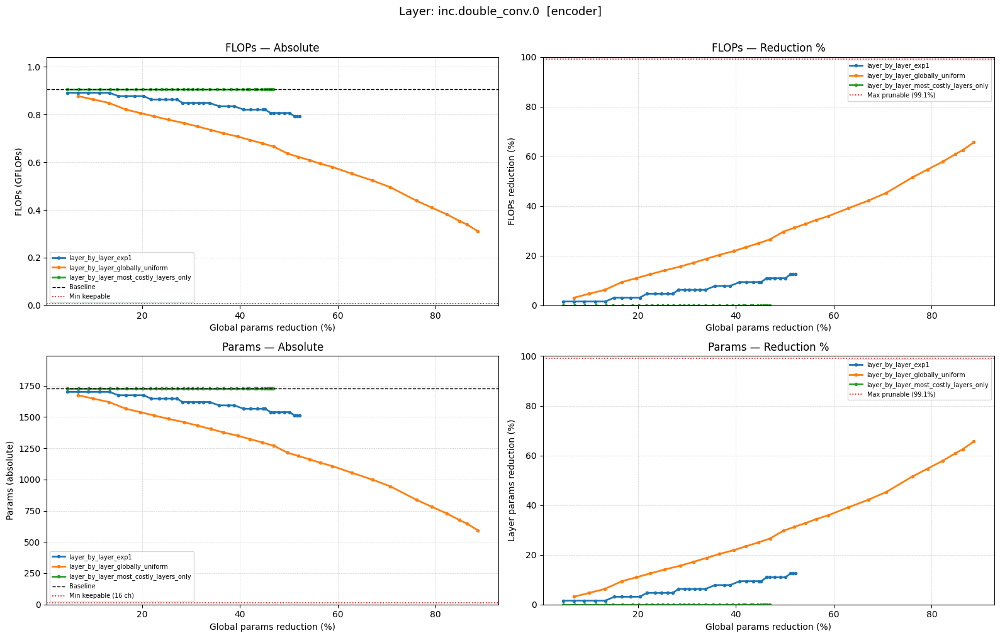

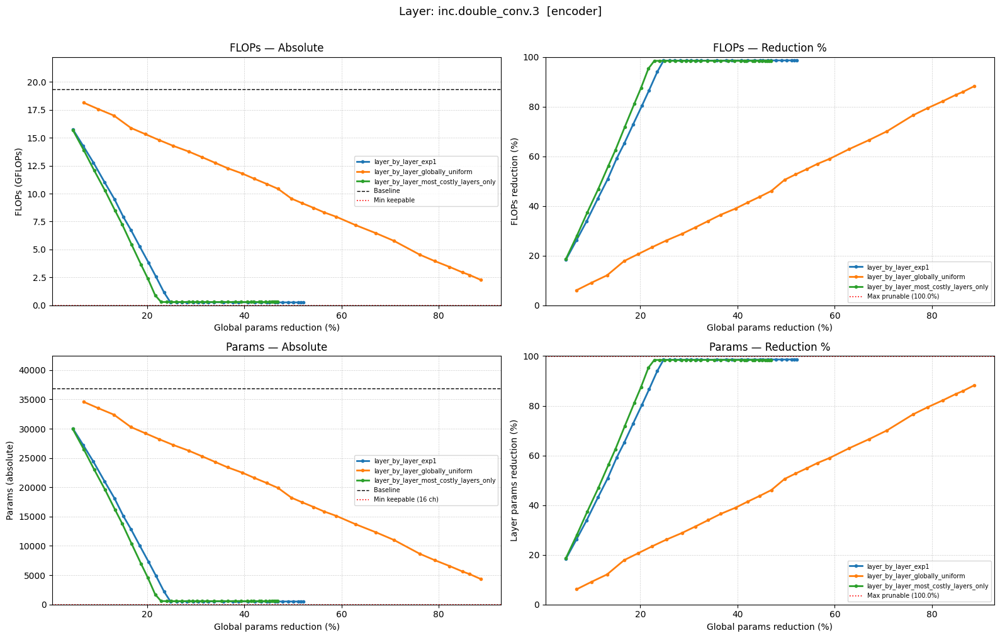

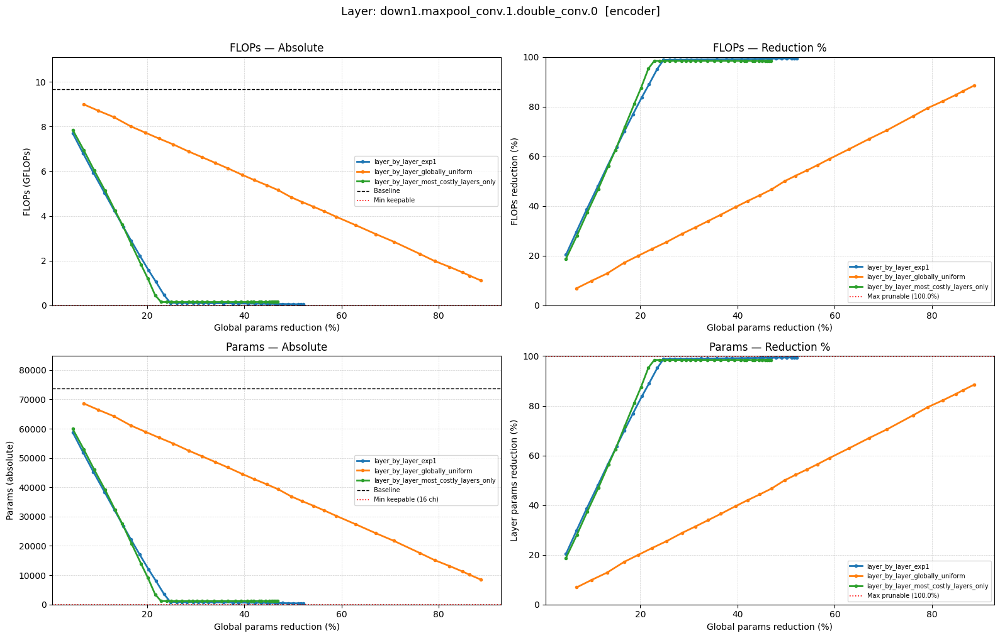

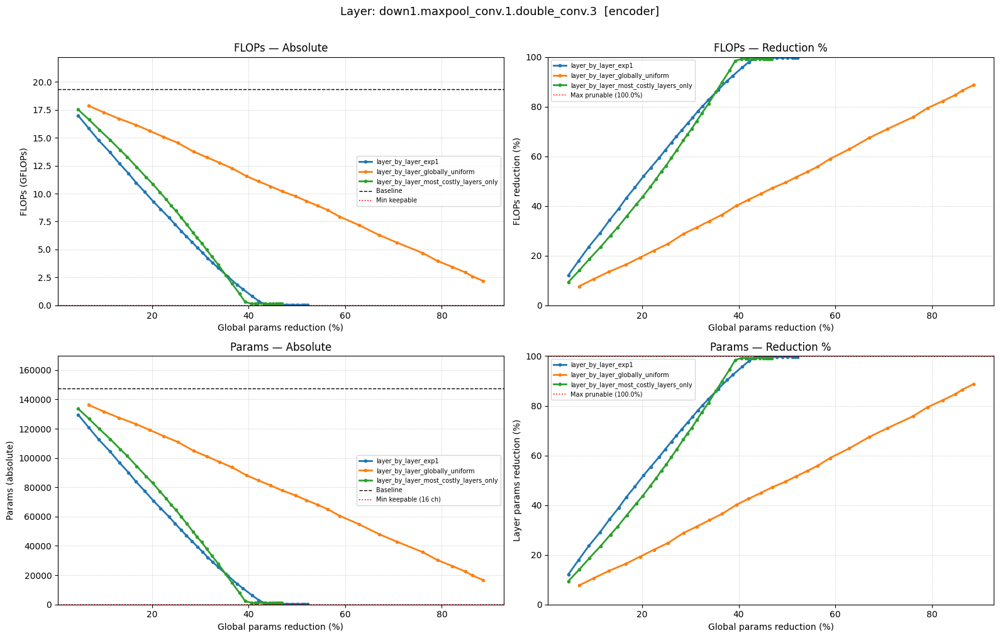

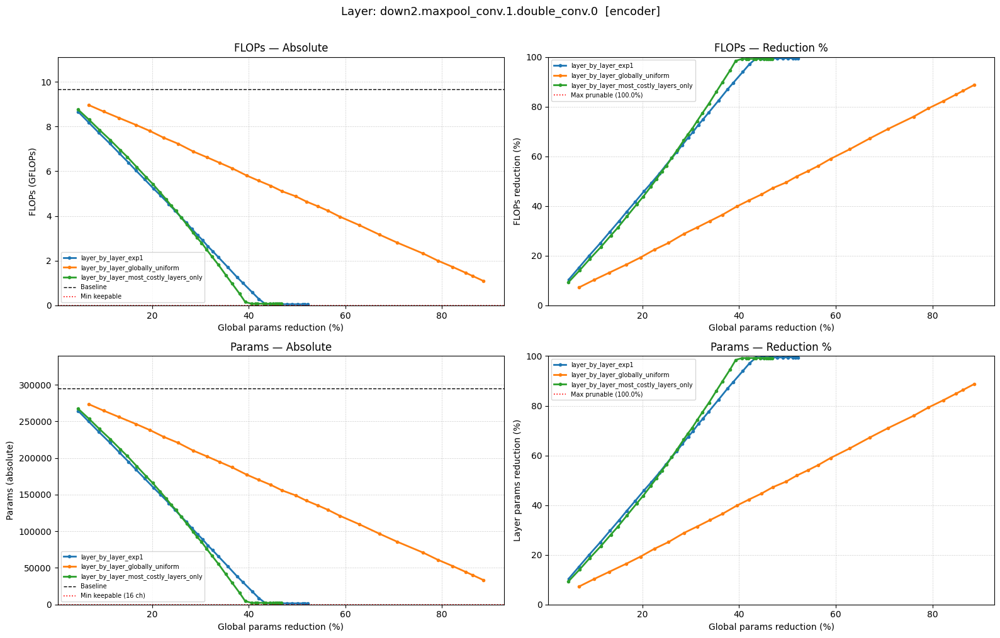

...

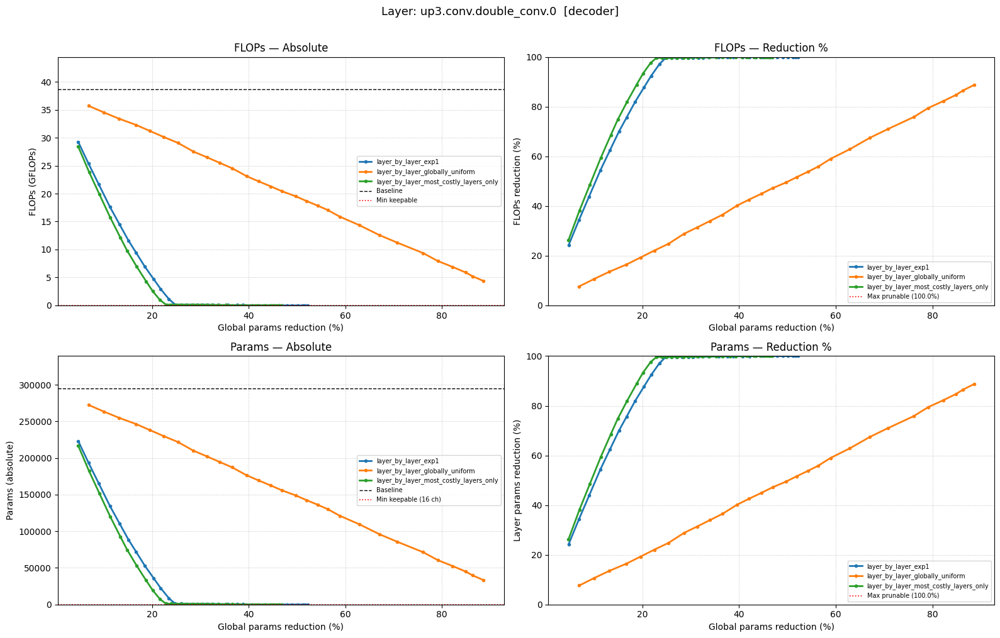

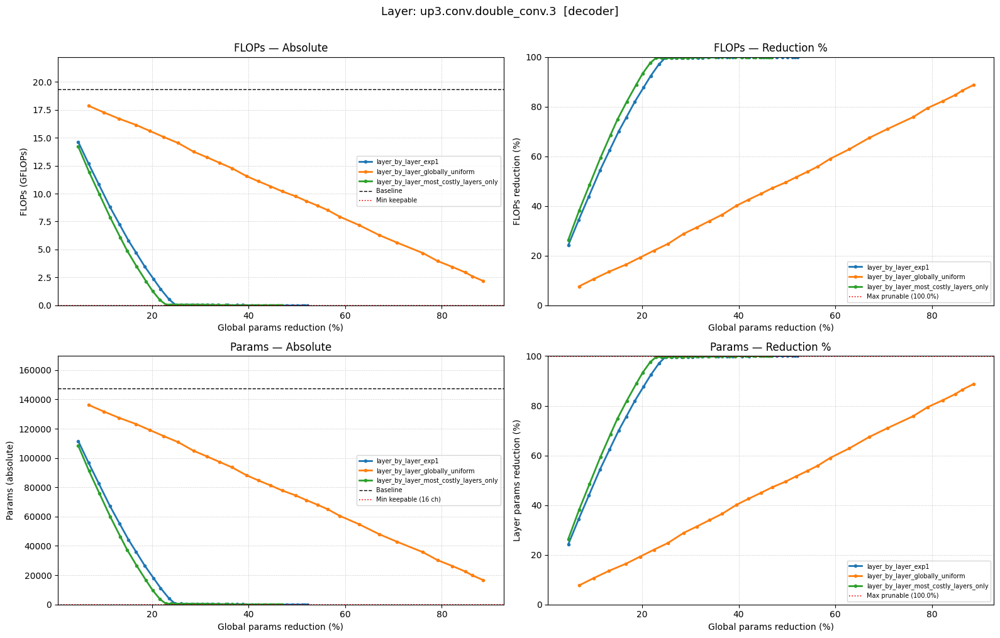

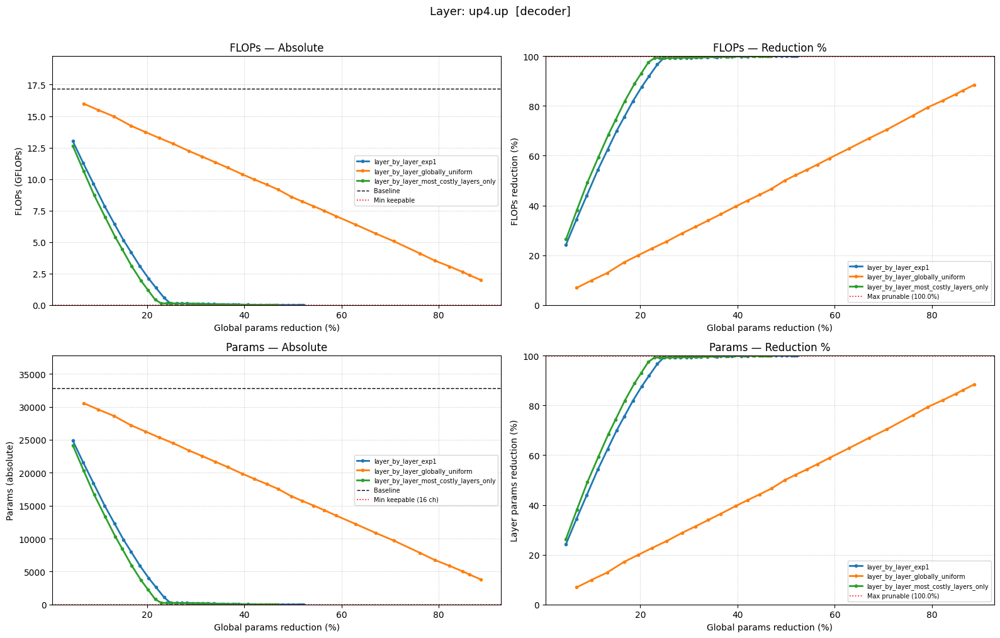

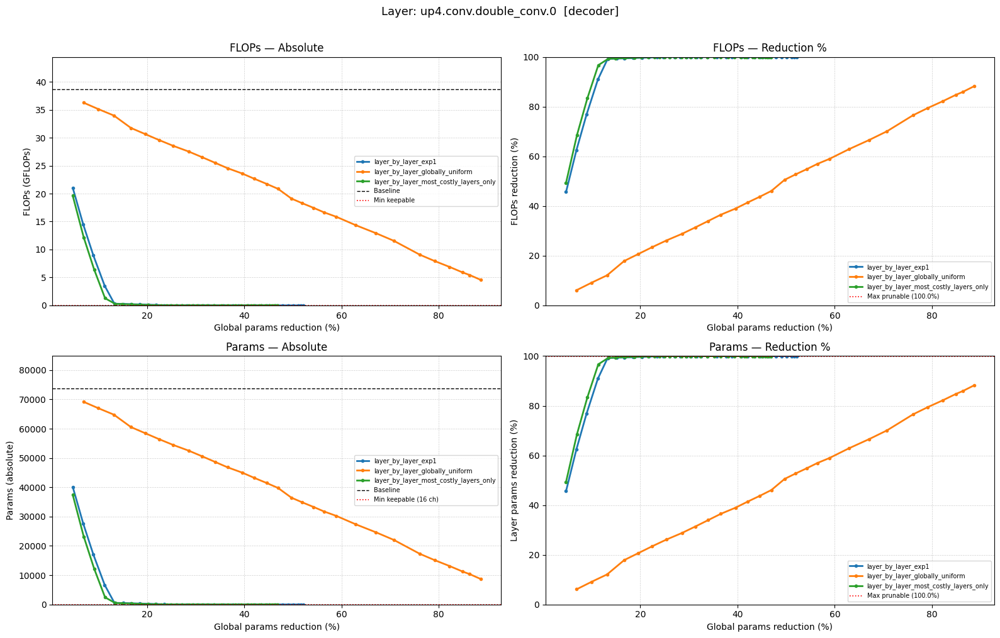

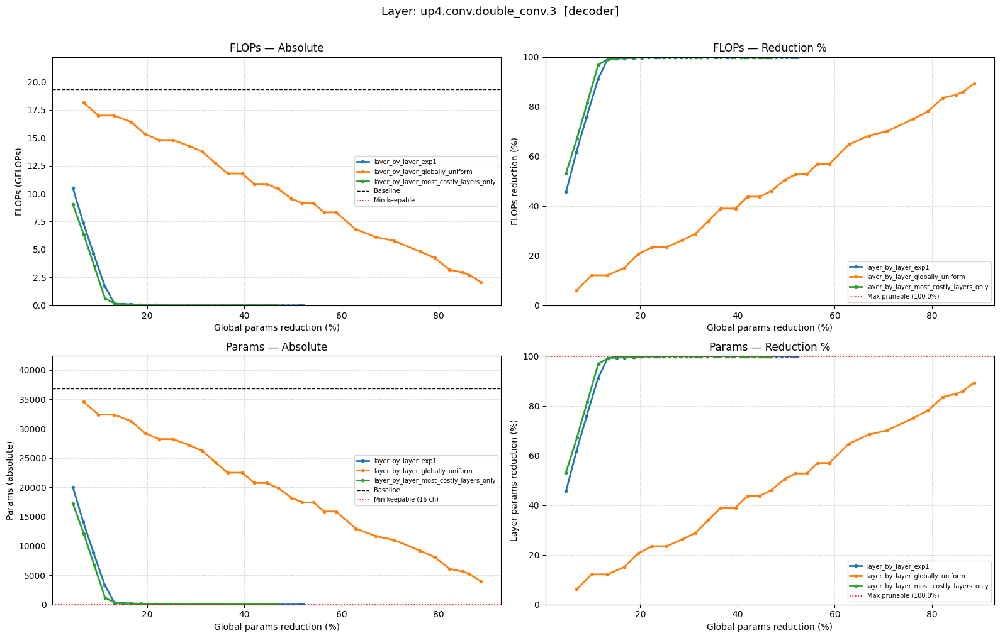

In [15]:
for nm in layer_names:
    df_l = df_layer_plot[df_layer_plot["layer_name"] == nm]
    if df_l.empty:
        continue

    f_base_g = baseline_layer_stats[nm][0] * flops_mult / 1e9
    p_base   = baseline_layer_stats[nm][1]

    # theoretical max prunable (min 16 channels kept)
    min_keep       = 16
    max_prune_pct_params = 100 * (1 - min_keep / p_base) if p_base > 0 else 100
    max_prune_pct_flops  = max_prune_pct_params  # proportional approximation

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle(f"Layer: {nm}  [{_group_of(nm)}]", fontsize=13, y=1.01)

    # ── FLOPs absolute ────────────────────────────────────────────────────────
    ax = axes[0, 0]
    for strat in strategies:
        d = df_l[df_l["pruning_strategy"] == strat].sort_values("params_reduction_pct")
        ax.plot(d["params_reduction_pct"], d["flops_pruned_g"],
                marker="o", markersize=3, lw=2, label=strat, color=STRATEGY_COLORS.get(strat))
    ax.axhline(f_base_g, color="black", linestyle="--", linewidth=1, label="Baseline")
    ax.axhline(f_base_g * (1 - max_prune_pct_flops / 100), color="red",
               linestyle=":", linewidth=1.2, label=f"Min keepable")
    ax.set_ylim(0, f_base_g * 1.15)
    ax.set_xlabel("Global params reduction (%)")
    ax.set_ylabel("FLOPs (GFLOPs)")
    ax.set_title("FLOPs — Absolute")
    ax.legend(fontsize=7)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

    # ── FLOPs % ───────────────────────────────────────────────────────────────
    ax = axes[0, 1]
    for strat in strategies:
        d = df_l[df_l["pruning_strategy"] == strat].sort_values("params_reduction_pct")
        ax.plot(d["params_reduction_pct"], d["flops_reduction_pct"],
                marker="o", markersize=3, lw=2, label=strat, color=STRATEGY_COLORS.get(strat))
    ax.axhline(max_prune_pct_flops, color="red", linestyle=":",
               linewidth=1.2, label=f"Max prunable ({max_prune_pct_flops:.1f}%)")
    ax.set_ylim(0, 100)
    ax.set_xlabel("Global params reduction (%)")
    ax.set_ylabel("FLOPs reduction (%)")
    ax.set_title("FLOPs — Reduction %")
    ax.legend(fontsize=7)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

    # ── Params absolute ───────────────────────────────────────────────────────
    ax = axes[1, 0]
    for strat in strategies:
        d = df_l[df_l["pruning_strategy"] == strat].sort_values("params_reduction_pct")
        ax.plot(d["params_reduction_pct"], d["params_pruned"],
                marker="o", markersize=3, lw=2, label=strat, color=STRATEGY_COLORS.get(strat))
    ax.axhline(p_base, color="black", linestyle="--", linewidth=1, label="Baseline")
    ax.axhline(min_keep * (p_base / max(baseline_layer_stats[nm][1], 1)),
               color="red", linestyle=":", linewidth=1.2, label=f"Min keepable ({min_keep} ch)")
    ax.set_ylim(0, p_base * 1.15)
    ax.set_xlabel("Global params reduction (%)")
    ax.set_ylabel("Params (absolute)")
    ax.set_title("Params — Absolute")
    ax.legend(fontsize=7)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

    # ── Params % ──────────────────────────────────────────────────────────────
    ax = axes[1, 1]
    for strat in strategies:
        d = df_l[df_l["pruning_strategy"] == strat].sort_values("params_reduction_pct")
        ax.plot(d["params_reduction_pct"], d["params_reduction_pct_layer"],
                marker="o", markersize=3, lw=2, label=strat, color=STRATEGY_COLORS.get(strat))
    ax.axhline(max_prune_pct_params, color="red", linestyle=":",
               linewidth=1.2, label=f"Max prunable ({max_prune_pct_params:.1f}%)")
    ax.set_ylim(0, 100)
    ax.set_xlabel("Global params reduction (%)")
    ax.set_ylabel("Layer params reduction (%)")
    ax.set_title("Params — Reduction %")
    ax.legend(fontsize=7)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

    plt.tight_layout()
    plt.show()

In [16]:
import os, time
import numpy as np
import pandas as pd
from pathlib import Path
import torch

DEVICE     = "cuda" if torch.cuda.is_available() else "cpu"
IMG_SIZE   = 512
BATCH_SIZE = 1
WARMUP     = 30
RUNS       = 400
USE_FP16   = False
DTYPE      = torch.float16 if (USE_FP16 and DEVICE == "cuda") else torch.float32


KEEP_STRATEGIES = [
    "layer_by_layer_exp1",
    "layer_by_layer_globally_uniform",
    "layer_by_layer_most_costly_layers_only",
]

def build_model_for_checkpoint(channel_txt_path=None):
    return UNet(
        n_channels=3,
        n_classes=2,
        f_channels=channel_txt_path,
    )

def _safe_load_sd(path):
    try:    return torch.load(path, map_location="cpu", weights_only=True)
    except TypeError: return torch.load(path, map_location="cpu")

def _load_model_gpu(ckpt_path, channels_txt):
    m = build_model_for_checkpoint(str(channels_txt)).to(DEVICE)
    sd = _safe_load_sd(str(ckpt_path))
    if any(k.startswith("module.") for k in sd):
        sd = {k.replace("module.", "", 1): v for k, v in sd.items()}
    m.load_state_dict(sd, strict=True)
    m.eval()
    if DEVICE == "cuda":
        m = m.to(memory_format=torch.channels_last)
    if USE_FP16 and DEVICE == "cuda":
        m = m.half()
    return m

@torch.no_grad()
def measure_lat_p50(model, img_size, warmup, runs):
    x = torch.randn(BATCH_SIZE, 3, img_size, img_size, device=DEVICE, dtype=DTYPE)
    if DEVICE == "cuda":
        x = x.to(memory_format=torch.channels_last)
    for _ in range(warmup):
        _ = model(x)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    times = []
    for _ in range(runs):
        if DEVICE == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        _ = model(x)
        if DEVICE == "cuda": torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000.0)
    return float(np.percentile(np.array(times), 50))

def _run_dir(log_path):
    p = Path(str(log_path))
    return p.parent if p.name.lower() == "log.txt" else p.parent

def _find_ckpt_and_ch(run_dir):
    run_dir = Path(run_dir)
    for name in ["Finetuned.pth", "finetuned.pth"]:
        p = run_dir / name
        if p.exists():
            ckpt = p; break
    else:
        cands = [p for p in run_dir.glob("*.pth") if "finetuned" in p.name.lower()]
        if not cands: raise FileNotFoundError(f"No finetuned ckpt in {run_dir}")
        ckpt = sorted(cands, key=lambda p: p.stat().st_size, reverse=True)[0]
    ch = run_dir / "pruned_channels.txt"
    if not ch.exists(): raise FileNotFoundError(f"No pruned_channels.txt in {run_dir}")
    return ckpt, ch

# ── Baseline ─────────────────────────────────────────────────────────────────
base_model = _load_model_gpu(Path(BASELINE_CKPT), Path(BASELINE_CHANNELS_TXT))
baseline_lat_p50 = measure_lat_p50(base_model, IMG_SIZE, WARMUP, RUNS)
del base_model
if DEVICE == "cuda": torch.cuda.empty_cache()
print(f"Baseline GPU p50: {baseline_lat_p50:.3f} ms")

# ── All runs ──────────────────────────────────────────────────────────────────
src = df_runs.copy()
src = src[src["pruning_strategy"].isin(KEEP_STRATEGIES)].copy()

rows, fail = [], []
for _, r in src.iterrows():
    try:
        rd   = _run_dir(r["log_path"])
        ckpt, ch = _find_ckpt_and_ch(rd)
        m    = _load_model_gpu(ckpt, ch)
        p50  = measure_lat_p50(m, IMG_SIZE, WARMUP, RUNS)
        rows.append({
            "log_path":         r["log_path"],
            "pruning_strategy": r["pruning_strategy"],
            "experiment_type":  r.get("experiment_type", "global"),
            "budget_x":         r.get("budget_x", np.nan),
            "model_name":       r.get("model_name", ""),
            "lat_ms_p50":       p50,
        })
        del m
    except Exception as e:
        fail.append((r.get("model_name",""), repr(e)))
    finally:
        if DEVICE == "cuda": torch.cuda.empty_cache()

df_latency_all = pd.DataFrame(rows)
print(f"Benchmarked: {len(df_latency_all)} / {len(src)}  |  failures: {len(fail)}")
if fail:
    for x in fail[:10]: print(" -", x)
display(df_latency_all)

Baseline GPU p50: 17.404 ms
Benchmarked: 101 / 101  |  failures: 0


,log_path,pruning_strategy,experiment_type,budget_x,model_name,lat_ms_p50
0,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_exp1,global,NaN,layer_by_layer_exp1__global_u200_e208,27.7092
1,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_exp1,global,NaN,layer_by_layer_exp1__global_u300_e304,18.3879
2,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_exp1,global,NaN,layer_by_layer_exp1__global_u400_e400,23.5838
3,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_exp1,global,NaN,layer_by_layer_exp1__global_u500_e512,23.7543
4,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_exp1,global,NaN,layer_by_layer_exp1__global_u600_e608,15.1989
...,...,...,...,...,...,...
96,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_most_costly_layers_only,global,NaN,layer_by_layer_most_costly_layers_only__global...,7.6533
97,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_most_costly_layers_only,global,NaN,layer_by_layer_most_costly_layers_only__global...,7.8184
98,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_most_costly_layers_only,global,NaN,layer_by_layer_most_costly_layers_only__global...,8.0190
99,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_most_costly_layers_only,global,NaN,layer_by_layer_most_costly_layers_only__global...,7.2706


In [17]:
import os, time
import numpy as np
import pandas as pd
from pathlib import Path
import torch

CPU_THREADS = min(os.cpu_count() or 8, 32)
torch.set_num_threads(CPU_THREADS)
CPU_IMG_SIZE = 512
CPU_WARMUP   = 5
CPU_RUNS     = 100

KEEP_STRATEGIES = [
    "layer_by_layer_exp1",
    "global_exp1",
    "layer_by_layer_globally_uniform",
    "layer_by_layer_most_costly_layers_only",
]

def _safe_load_sd_cpu(path):
    try:    return torch.load(path, map_location="cpu", weights_only=True)
    except TypeError: return torch.load(path, map_location="cpu")

def _load_model_cpu(ckpt_path, channels_txt):
    m = build_model_for_checkpoint(str(channels_txt)).to("cpu")
    sd = _safe_load_sd_cpu(str(ckpt_path))
    if any(k.startswith("module.") for k in sd):
        sd = {k.replace("module.", "", 1): v for k, v in sd.items()}
    m.load_state_dict(sd, strict=True)
    m.eval()
    return m

@torch.inference_mode()
def _latency_cpu_p50_ms(model, img_size, warmup, runs):
    x = torch.randn(1, 3, img_size, img_size, dtype=torch.float32)
    for _ in range(warmup): _ = model(x)
    times = np.empty(runs, dtype=np.float64)
    for i in range(runs):
        t0 = time.perf_counter()
        _ = model(x)
        times[i] = (time.perf_counter() - t0) * 1000.0
    return float(np.percentile(times, 50))

def _run_dir(log_path):
    p = Path(str(log_path))
    return p.parent if p.name.lower() == "log.txt" else p.parent

def _find_ckpt_and_ch(run_dir):
    run_dir = Path(run_dir)
    for name in ["Finetuned.pth", "finetuned.pth"]:
        p = run_dir / name
        if p.exists():
            ckpt = p; break
    else:
        cands = [p for p in run_dir.glob("*.pth") if "finetuned" in p.name.lower()]
        if not cands: raise FileNotFoundError(f"No finetuned ckpt in {run_dir}")
        ckpt = sorted(cands, key=lambda p: p.stat().st_size, reverse=True)[0]
    ch = run_dir / "pruned_channels.txt"
    if not ch.exists(): raise FileNotFoundError(f"No pruned_channels.txt in {run_dir}")
    return ckpt, ch

# ── Baseline ──────────────────────────────────────────────────────────────────
base_model = _load_model_cpu(Path(BASELINE_CKPT), Path(BASELINE_CHANNELS_TXT))
baseline_cpu_p50 = _latency_cpu_p50_ms(base_model, CPU_IMG_SIZE, CPU_WARMUP, CPU_RUNS)
del base_model
print(f"Baseline CPU p50: {baseline_cpu_p50:.3f} ms  (threads={CPU_THREADS})")

# ── All runs ──────────────────────────────────────────────────────────────────
src = df_runs.copy()
src = src[src["pruning_strategy"].isin(KEEP_STRATEGIES)].copy()

rows, fail = [], []
for _, r in src.iterrows():
    try:
        rd   = _run_dir(r["log_path"])
        ckpt, ch = _find_ckpt_and_ch(rd)
        m    = _load_model_cpu(ckpt, ch)
        p50  = _latency_cpu_p50_ms(m, CPU_IMG_SIZE, CPU_WARMUP, CPU_RUNS)
        rows.append({
            "log_path":         r["log_path"],
            "pruning_strategy": r["pruning_strategy"],
            "experiment_type":  r.get("experiment_type", "global"),
            "budget_x":         r.get("budget_x", np.nan),
            "model_name":       r.get("model_name", ""),
            "lat_ms_p50":       p50,
        })
        del m
    except Exception as e:
        fail.append((r.get("model_name",""), repr(e)))

df_latency_cpu = pd.DataFrame(rows)
print(f"Benchmarked: {len(df_latency_cpu)} / {len(src)}  |  failures: {len(fail)}")
if fail:
    for x in fail[:10]: print(" -", x)
display(df_latency_cpu)

Baseline CPU p50: 858.498 ms  (threads=32)
Benchmarked: 101 / 101  |  failures: 0


,log_path,pruning_strategy,experiment_type,budget_x,model_name,lat_ms_p50
0,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_exp1,global,NaN,layer_by_layer_exp1__global_u200_e208,696.9190
1,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_exp1,global,NaN,layer_by_layer_exp1__global_u300_e304,611.0662
2,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_exp1,global,NaN,layer_by_layer_exp1__global_u400_e400,600.9085
3,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_exp1,global,NaN,layer_by_layer_exp1__global_u500_e512,522.2969
4,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_exp1,global,NaN,layer_by_layer_exp1__global_u600_e608,485.4286
...,...,...,...,...,...,...
96,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_most_costly_layers_only,global,NaN,layer_by_layer_most_costly_layers_only__global...,198.4828
97,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_most_costly_layers_only,global,NaN,layer_by_layer_most_costly_layers_only__global...,199.1277
98,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_most_costly_layers_only,global,NaN,layer_by_layer_most_costly_layers_only__global...,203.7328
99,/home/jovyan/cost-based-pruning-layer-by-layer...,layer_by_layer_most_costly_layers_only,global,NaN,layer_by_layer_most_costly_layers_only__global...,192.3544


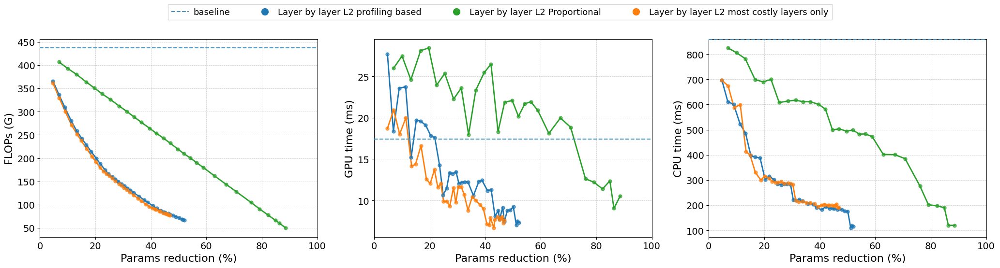

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D

mpl.rcParams.update({
    "font.size": 18, "axes.titlesize": 18, "axes.labelsize": 16,
    "xtick.labelsize": 14, "ytick.labelsize": 14,
    "legend.fontsize": 14, "figure.titlesize": 18,
})

MAX_X = 100.0  # show full range since your experiments go higher than old ones

LABEL_MAP = {
    "layer_by_layer_exp1":                  "Layer by layer L2 profiling based",
    "layer_by_layer_globally_uniform":      "Layer by layer L2 Proportional",
    "layer_by_layer_most_costly_layers_only": "Layer by layer L2 most costly layers only",
}
COLOR_MAP = {
    "layer_by_layer_exp1":                  "#1f77b4",   # blue
    "layer_by_layer_globally_uniform":      "#2ca02c",   # green
    "layer_by_layer_most_costly_layers_only": "#ff7f0e", # orange
}
STRATEGIES = list(LABEL_MAP.keys())

AGG_FN         = "median"
ENFORCE_MONO_X = True
SCATTER_ALPHA  = 0.7
SCATTER_SIZE   = 25
LINE_WIDTH     = 2.0

def _num(s): return pd.to_numeric(s, errors="coerce")

def _choose_order_col(df):
    for c in ["removed_channels_reported", "requested_budget_channels", "budget_x"]:
        if c in df.columns and _num(df[c]).notna().any(): return c
    return None

def _build_connected_line(df_one_strat):
    d = df_one_strat.copy()
    d["x"] = _num(d["x"]); d["y"] = _num(d["y"])
    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=["x","y"])
    d = d[d["x"] <= MAX_X].copy()
    if d.empty: return None
    oc = _choose_order_col(d)
    if oc is None:
        line = d.sort_values("x")[["x","y"]].copy()
    else:
        d[oc] = _num(d[oc]); d = d.dropna(subset=[oc])
        if d.empty: return None
        g = getattr(d.groupby(oc)[["x","y"]], AGG_FN)().reset_index().sort_values(oc)
        line = g[["x","y"]].copy()
    if ENFORCE_MONO_X and len(line) >= 2:
        line["x"] = np.maximum.accumulate(line["x"].values)
    return line

def _panel(ax, df, ylabel, baseline=None):
    for strat in STRATEGIES:
        color = COLOR_MAP.get(strat)
        dt = df[df["pruning_strategy"] == strat].copy()
        dt["x"] = _num(dt["x"]); dt["y"] = _num(dt["y"])
        dt = dt.replace([np.inf, -np.inf], np.nan).dropna(subset=["x","y"])
        dt = dt[dt["x"] <= MAX_X].copy()
        if dt.empty: continue
        ax.scatter(dt["x"], dt["y"], s=SCATTER_SIZE, alpha=SCATTER_ALPHA,
                   color=color, label=LABEL_MAP.get(strat, strat), zorder=3)
        line = _build_connected_line(dt)
        if line is not None and len(line) >= 2:
            ax.plot(line["x"], line["y"], linewidth=LINE_WIDTH, color=color, zorder=2)
    if baseline is not None:
        ax.axhline(float(baseline), linestyle="--", linewidth=1.5, color="#4393c3", zorder=4)
    ax.set_xlabel("Params reduction (%)", fontsize=16)
    ax.set_ylabel(ylabel, fontsize=16)
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
    ax.set_xlim(0, MAX_X)

# ── Build fl ──────────────────────────────────────────────────────────────────
# FLOPs: use recomputed values from gplot (already has flops_g_pruned_recomputed)
fl = gplot.copy()
fl["x"] = _num(fl["params_reduction_pct"]).clip(0, 100)
fl["y"] = _num(fl["flops_g_pruned_recomputed"])   # use recomputed, not logged
baseline_flops_g_val = baseline_flops_g  # from the recompute cell

# ── Build gpu ─────────────────────────────────────────────────────────────────
gpu = df_latency_all.copy()
# merge params_reduction_pct from df_runs
right = df_runs[["log_path","params_reduction_pct"]].drop_duplicates("log_path")
gpu = gpu.merge(right, on="log_path", how="left")
gpu["x"] = _num(gpu["params_reduction_pct"]).clip(0, 100)
gpu["y"] = _num(gpu["lat_ms_p50"])

# ── Build cpu ─────────────────────────────────────────────────────────────────
cpu = df_latency_cpu.copy()
cpu = cpu.merge(right, on="log_path", how="left")
cpu["x"] = _num(cpu["params_reduction_pct"]).clip(0, 100)
cpu["y"] = _num(cpu["lat_ms_p50"])

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(21, 5.2), sharex=True)

_panel(axes[0], fl,  "FLOPs (G)",      baseline=baseline_flops_g_val)
_panel(axes[1], gpu, "GPU time (ms)",   baseline=baseline_lat_p50)
_panel(axes[2], cpu, "CPU time (ms)",   baseline=baseline_cpu_p50)

legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor=COLOR_MAP[s], markersize=12, label=LABEL_MAP[s])
    for s in STRATEGIES
]
baseline_handle = Line2D([0], [0], linestyle="--", linewidth=1.5,
                          color="#4393c3", label="baseline")

fig.legend(
    handles=[baseline_handle] + legend_handles,
    loc="upper center", ncol=len(STRATEGIES)+1,
    bbox_to_anchor=(0.5, 1.1), frameon=True,
    edgecolor="#cccccc", fancybox=False,
    fontsize=13, handletextpad=0.5, columnspacing=3,
)
plt.tight_layout()
plt.savefig("paper_figure_new_experiments.pdf", bbox_inches="tight")
plt.savefig("paper_figure_new_experiments_lbl_l2.png", dpi=300, bbox_inches="tight")
plt.show()

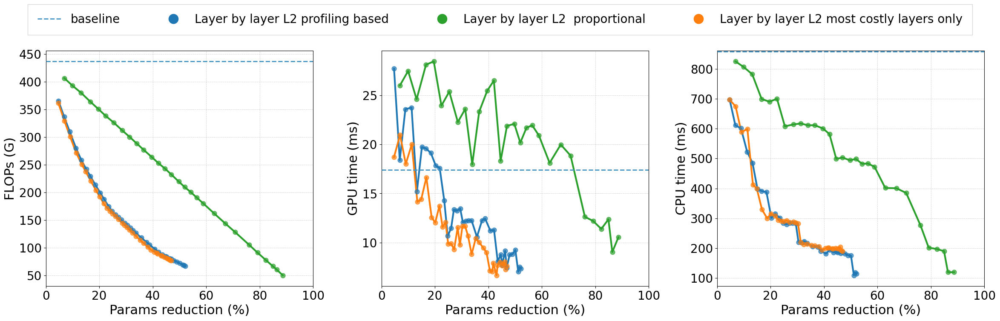

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D

# ── Bigger global fonts ──────────────────────────────────────────────────────
mpl.rcParams.update({
    "font.size": 24,
    "axes.titlesize": 24,
    "axes.labelsize": 22,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20,
    "figure.titlesize": 24,
})

MAX_X = 100.0  # show full range since your experiments go higher than old ones

LABEL_MAP = {
    "layer_by_layer_exp1": "Layer by layer L2 profiling based",
    "layer_by_layer_globally_uniform": "Layer by layer L2  proportional",
    "layer_by_layer_most_costly_layers_only": "Layer by layer L2 most costly layers only",
}

COLOR_MAP = {
    "layer_by_layer_exp1": "#1f77b4",   # blue
    "layer_by_layer_globally_uniform": "#2ca02c",   # green
    "layer_by_layer_most_costly_layers_only": "#ff7f0e", # orange
}

STRATEGIES = list(LABEL_MAP.keys())

AGG_FN         = "median"
ENFORCE_MONO_X = True
SCATTER_ALPHA  = 0.7

# ── Bigger scatter points and lines ──────────────────────────────────────────
SCATTER_SIZE   = 60
LINE_WIDTH     = 3.0


def _num(s):
    return pd.to_numeric(s, errors="coerce")


def _choose_order_col(df):
    for c in ["removed_channels_reported", "requested_budget_channels", "budget_x"]:
        if c in df.columns and _num(df[c]).notna().any():
            return c
    return None


def _build_connected_line(df_one_strat):
    d = df_one_strat.copy()

    d["x"] = _num(d["x"])
    d["y"] = _num(d["y"])

    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=["x", "y"])
    d = d[d["x"] <= MAX_X].copy()

    if d.empty:
        return None

    oc = _choose_order_col(d)

    if oc is None:
        line = d.sort_values("x")[["x", "y"]].copy()
    else:
        d[oc] = _num(d[oc])
        d = d.dropna(subset=[oc])

        if d.empty:
            return None

        g = getattr(d.groupby(oc)[["x", "y"]], AGG_FN)() \
            .reset_index() \
            .sort_values(oc)

        line = g[["x", "y"]].copy()

    if ENFORCE_MONO_X and len(line) >= 2:
        line["x"] = np.maximum.accumulate(line["x"].values)

    return line


def _panel(ax, df, ylabel, baseline=None):

    for strat in STRATEGIES:

        color = COLOR_MAP.get(strat)

        dt = df[df["pruning_strategy"] == strat].copy()

        dt["x"] = _num(dt["x"])
        dt["y"] = _num(dt["y"])

        dt = dt.replace([np.inf, -np.inf], np.nan) \
               .dropna(subset=["x", "y"])

        dt = dt[dt["x"] <= MAX_X].copy()

        if dt.empty:
            continue

        # ── Bigger scatter markers ───────────────────────────────────────────
        ax.scatter(
            dt["x"],
            dt["y"],
            s=SCATTER_SIZE,
            alpha=SCATTER_ALPHA,
            color=color,
            label=LABEL_MAP.get(strat, strat),
            zorder=3
        )

        line = _build_connected_line(dt)

        if line is not None and len(line) >= 2:
            ax.plot(
                line["x"],
                line["y"],
                linewidth=LINE_WIDTH,
                color=color,
                zorder=2
            )

    if baseline is not None:
        ax.axhline(
            float(baseline),
            linestyle="--",
            linewidth=2.0,
            color="#4393c3",
            zorder=4
        )

    # ── Bigger axis labels ───────────────────────────────────────────────────
    ax.set_xlabel("Params reduction (%)", fontsize=22)
    ax.set_ylabel(ylabel, fontsize=22)

    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

    ax.set_xlim(0, MAX_X)


# ── Build fl ─────────────────────────────────────────────────────────────────
fl = gplot.copy()

fl["x"] = _num(fl["params_reduction_pct"]).clip(0, 100)

fl["y"] = _num(fl["flops_g_pruned_recomputed"])

baseline_flops_g_val = baseline_flops_g


# ── Build gpu ────────────────────────────────────────────────────────────────
gpu = df_latency_all.copy()

right = df_runs[
    ["log_path", "params_reduction_pct"]
].drop_duplicates("log_path")

gpu = gpu.merge(right, on="log_path", how="left")

gpu["x"] = _num(gpu["params_reduction_pct"]).clip(0, 100)

gpu["y"] = _num(gpu["lat_ms_p50"])


# ── Build cpu ────────────────────────────────────────────────────────────────
cpu = df_latency_cpu.copy()

cpu = cpu.merge(right, on="log_path", how="left")

cpu["x"] = _num(cpu["params_reduction_pct"]).clip(0, 100)

cpu["y"] = _num(cpu["lat_ms_p50"])


# ── Bigger figure size ───────────────────────────────────────────────────────
fig, axes = plt.subplots(
    1,
    3,
    figsize=(24, 7),
    sharex=True
)

_panel(
    axes[0],
    fl,
    "FLOPs (G)",
    baseline=baseline_flops_g_val
)

_panel(
    axes[1],
    gpu,
    "GPU time (ms)",
    baseline=baseline_lat_p50
)

_panel(
    axes[2],
    cpu,
    "CPU time (ms)",
    baseline=baseline_cpu_p50
)


# ── Bigger legend circles ────────────────────────────────────────────────────
legend_handles = [
    Line2D(
        [0],
        [0],
        marker='o',
        color='w',
        markerfacecolor=COLOR_MAP[s],
        markersize=18,
        label=LABEL_MAP[s]
    )
    for s in STRATEGIES
]

baseline_handle = Line2D(
    [0],
    [0],
    linestyle="--",
    linewidth=2.0,
    color="#4393c3",
    label="baseline"
)


# ── Bigger legend text and spacing ───────────────────────────────────────────
fig.legend(
    handles=[baseline_handle] + legend_handles,
    loc="upper center",
    ncol=len(STRATEGIES) + 1,
    bbox_to_anchor=(0.5, 1.12),
    frameon=True,
    edgecolor="#cccccc",
    fancybox=False,
    fontsize=20,
    handletextpad=0.8,
    columnspacing=3.5,
    borderpad=0.8
)

plt.tight_layout()

plt.savefig(
    "paper_figure_new_experiments.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "paper_experiments_lbl_l2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

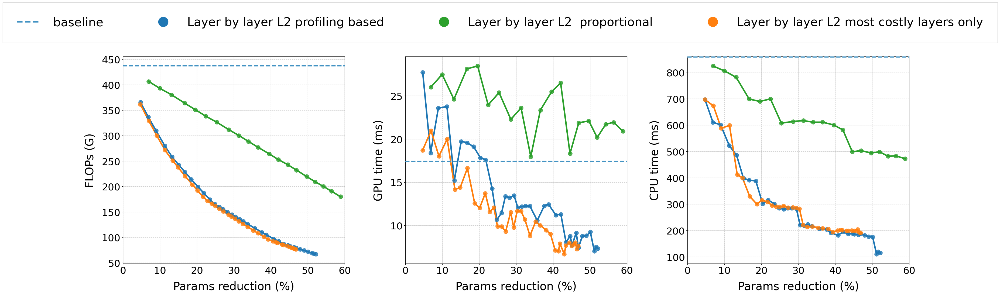

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D

# ── MUCH BIGGER GLOBAL FONTS ─────────────────────────────────────────────────
mpl.rcParams.update({
    "font.size": 40,
    "axes.titlesize": 32,
    "axes.labelsize": 30,
    "xtick.labelsize": 26,
    "ytick.labelsize": 26,
    "legend.fontsize": 40,
    "figure.titlesize": 32,
})

MAX_X = 60.0

STRATEGIES = list(LABEL_MAP.keys())

AGG_FN         = "median"
ENFORCE_MONO_X = True
SCATTER_ALPHA  = 0.8

# ── BIGGER SCATTER POINTS AND LINES ─────────────────────────────────────────
SCATTER_SIZE = 120
LINE_WIDTH   = 4.0


def _num(s):
    return pd.to_numeric(s, errors="coerce")


def _choose_order_col(df):
    for c in [
        "removed_channels_reported",
        "requested_budget_channels",
        "budget_x"
    ]:
        if c in df.columns and _num(df[c]).notna().any():
            return c
    return None


def _build_connected_line(df_one_strat):

    d = df_one_strat.copy()

    d["x"] = _num(d["x"])
    d["y"] = _num(d["y"])

    d = d.replace([np.inf, -np.inf], np.nan)
    d = d.dropna(subset=["x", "y"])

    d = d[d["x"] <= MAX_X].copy()

    if d.empty:
        return None

    oc = _choose_order_col(d)

    if oc is None:

        line = d.sort_values("x")[["x", "y"]].copy()

    else:

        d[oc] = _num(d[oc])

        d = d.dropna(subset=[oc])

        if d.empty:
            return None

        g = getattr(
            d.groupby(oc)[["x", "y"]],
            AGG_FN
        )().reset_index().sort_values(oc)

        line = g[["x", "y"]].copy()

    if ENFORCE_MONO_X and len(line) >= 2:
        line["x"] = np.maximum.accumulate(line["x"].values)

    return line


def _panel(ax, df, ylabel, baseline=None):

    for strat in STRATEGIES:

        color = COLOR_MAP.get(strat)

        dt = df[df["pruning_strategy"] == strat].copy()

        dt["x"] = _num(dt["x"])
        dt["y"] = _num(dt["y"])

        dt = dt.replace([np.inf, -np.inf], np.nan)
        dt = dt.dropna(subset=["x", "y"])

        dt = dt[dt["x"] <= MAX_X].copy()

        if dt.empty:
            continue

        # ── BIGGER COLORED CIRCLES IN PLOT ──────────────────────────────────
        ax.scatter(
            dt["x"],
            dt["y"],
            s=SCATTER_SIZE,
            alpha=SCATTER_ALPHA,
            color=color,
            label=LABEL_MAP.get(strat, strat),
            zorder=3
        )

        line = _build_connected_line(dt)

        if line is not None and len(line) >= 2:

            ax.plot(
                line["x"],
                line["y"],
                linewidth=LINE_WIDTH,
                color=color,
                zorder=2
            )

    if baseline is not None:

        ax.axhline(
            float(baseline),
            linestyle="--",
            linewidth=3.0,
            color="#4393c3",
            zorder=4
        )

    # ── MUCH BIGGER AXIS LABELS ─────────────────────────────────────────────
    ax.set_xlabel(
        "Params reduction (%)",
        fontsize=30,
        labelpad=15
    )

    ax.set_ylabel(
        ylabel,
        fontsize=30,
        labelpad=15
    )

    # ── BIGGER TICKS ────────────────────────────────────────────────────────
    ax.tick_params(axis='both', which='major', labelsize=26)

    ax.grid(
        True,
        linestyle="--",
        linewidth=1.0,
        alpha=0.6
    )

    ax.set_xlim(0, MAX_X)


# ── Build fl ─────────────────────────────────────────────────────────────────
fl = gplot.copy()

fl["x"] = _num(fl["params_reduction_pct"]).clip(0, 100)

fl["y"] = _num(fl["flops_g_pruned_recomputed"])

baseline_flops_g_val = baseline_flops_g


# ── Build gpu ────────────────────────────────────────────────────────────────
gpu = df_latency_all.copy()

right = df_runs[
    ["log_path", "params_reduction_pct"]
].drop_duplicates("log_path")

gpu = gpu.merge(right, on="log_path", how="left")

gpu["x"] = _num(gpu["params_reduction_pct"]).clip(0, 100)

gpu["y"] = _num(gpu["lat_ms_p50"])


# ── Build cpu ────────────────────────────────────────────────────────────────
cpu = df_latency_cpu.copy()

cpu = cpu.merge(right, on="log_path", how="left")

cpu["x"] = _num(cpu["params_reduction_pct"]).clip(0, 100)

cpu["y"] = _num(cpu["lat_ms_p50"])


# ── MUCH BIGGER FIGURE ───────────────────────────────────────────────────────
fig, axes = plt.subplots(
    1,
    3,
    figsize=(32, 10),
    sharex=True
)

_panel(
    axes[0],
    fl,
    "FLOPs (G)",
    baseline=baseline_flops_g_val
)

_panel(
    axes[1],
    gpu,
    "GPU time (ms)",
    baseline=baseline_lat_p50
)

_panel(
    axes[2],
    cpu,
    "CPU time (ms)",
    baseline=baseline_cpu_p50
)


# ── MUCH BIGGER LEGEND CIRCLES ──────────────────────────────────────────────
legend_handles = [
    Line2D(
        [0],
        [0],
        marker='o',
        color='w',
        markerfacecolor=COLOR_MAP[s],
        markersize=28,   # BIGGER LEGEND CIRCLES
        label=LABEL_MAP[s]
    )
    for s in STRATEGIES
]

baseline_handle = Line2D(
    [0],
    [0],
    linestyle="--",
    linewidth=4.0,
    color="#4393c3",
    label="baseline"
)


# ── MUCH BIGGER LEGEND TEXT + BOX ───────────────────────────────────────────
fig.legend(
    handles=[baseline_handle] + legend_handles,

    loc="upper center",

    ncol=len(STRATEGIES) + 1,

    bbox_to_anchor=(0.5, 1.16),

    frameon=True,

    edgecolor="#cccccc",

    fancybox=False,

    fontsize=32,   # BIGGER LEGEND WRITING

    handletextpad=1.0,

    columnspacing=4.0,

    borderpad=1.2
)

plt.tight_layout()

plt.savefig(
    "paper_taylorcarvana_l2_lbl.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "caravanaa_results_of_pruning_l2_lbl.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

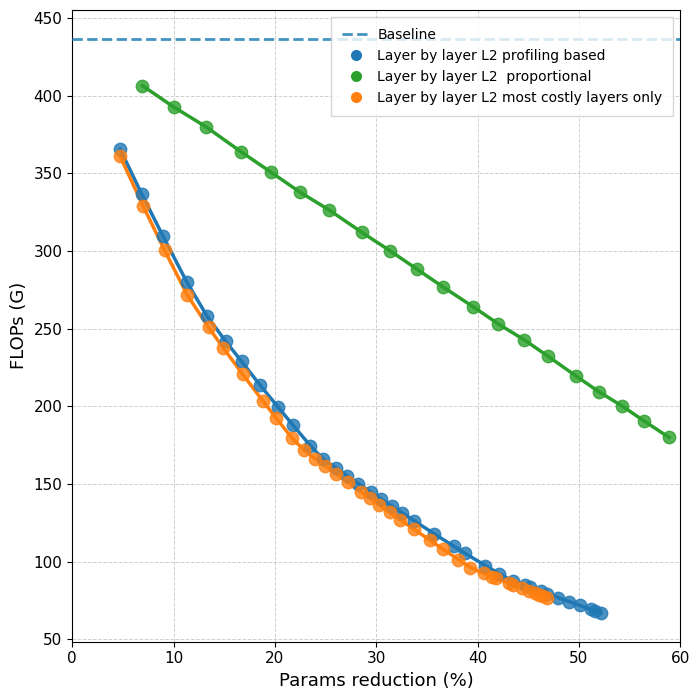

Saved: panel_flops.pdf / .png


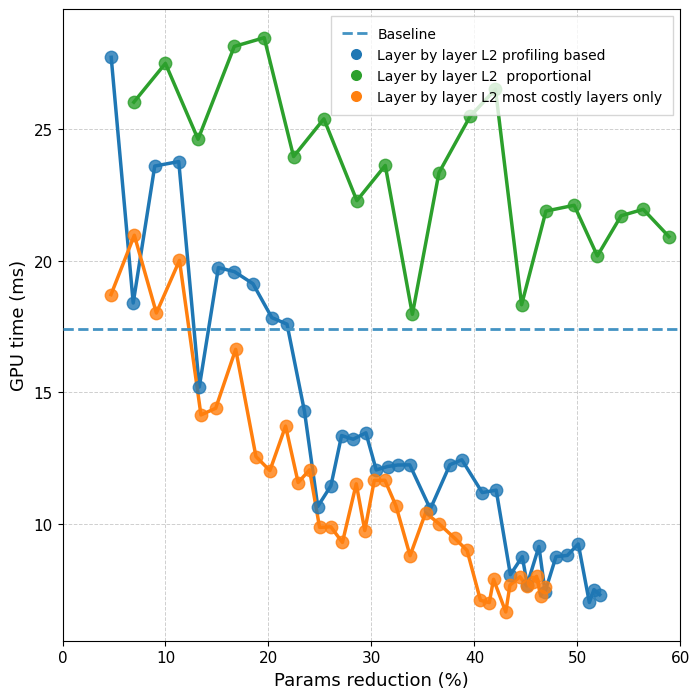

Saved: panel_gpu.pdf / .png


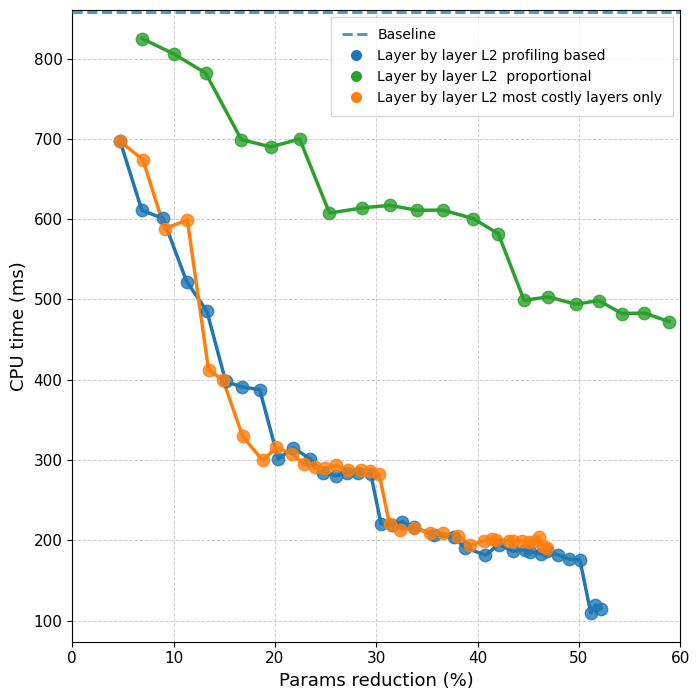

Saved: panel_cpu.pdf / .png


In [30]:
# ── Individual panels — one per metric, square, single column width ───────────

PANEL_CONFIGS = [
    ("fl",  "FLOPs (G)",      baseline_flops_g_val,  "flops"),
    ("gpu", "GPU time (ms)",  baseline_lat_p50,       "gpu"),
    ("cpu", "CPU time (ms)",  baseline_cpu_p50,       "cpu"),
]

for df_name, ylabel, baseline_val, file_suffix in PANEL_CONFIGS:
    df_panel = {"fl": fl, "gpu": gpu, "cpu": cpu}[df_name]

    fig, ax = plt.subplots(figsize=(8, 8))  # square = one column

    for strat in STRATEGIES:
        color = COLOR_MAP.get(strat)
        dt = df_panel[df_panel["pruning_strategy"] == strat].copy()
        dt["x"] = _num(dt["x"])
        dt["y"] = _num(dt["y"])
        dt = dt.replace([np.inf, -np.inf], np.nan).dropna(subset=["x", "y"])
        dt = dt[dt["x"] <= MAX_X].copy()
        if dt.empty:
            continue

        ax.scatter(dt["x"], dt["y"],
                   s=80, alpha=SCATTER_ALPHA,
                   color=color, zorder=3)

        line = _build_connected_line(dt)
        if line is not None and len(line) >= 2:
            ax.plot(line["x"], line["y"],
                    linewidth=2.5, color=color, zorder=2)

    if baseline_val is not None:
        ax.axhline(float(baseline_val),
                   linestyle="--", linewidth=2.0,
                   color="#4393c3", zorder=4)

    ax.set_xlabel("Params reduction (%)", fontsize=13)
    ax.set_ylabel(ylabel, fontsize=13)
    ax.tick_params(axis='both', labelsize=11)
    ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.6)
    ax.set_xlim(0, MAX_X)

    # ── Legend inside the plot, bottom left ──────────────────────────────
    legend_handles = [
        Line2D([0], [0], marker='o', color='w',
               markerfacecolor=COLOR_MAP[s], markersize=9,
               label=LABEL_MAP[s])
        for s in STRATEGIES
    ]
    baseline_handle = Line2D([0], [0], linestyle="--", linewidth=2.0,
                              color="#4393c3", label="Baseline")

    ax.legend(
        handles=[baseline_handle] + legend_handles,
        loc="upper right",
        fontsize=10,
        frameon=True,
        edgecolor="#cccccc",
        fancybox=False,
        handletextpad=0.5,
        borderpad=0.8,
    )

    plt.tight_layout()
    plt.savefig(f"panel_{file_suffix}.pdf", bbox_inches="tight")
    plt.savefig(f"panel_{file_suffix}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"Saved: panel_{file_suffix}.pdf / .png")

In [26]:
# Cell — Thesis summary table (target params reduction × strategy)
import pandas as pd
import numpy as np

BASELINE_DICE    = float(df_runs["dice_baseline"].dropna().iloc[0])
BASELINE_FLOPS_G = baseline_flops_g  # from recompute cell

# ── Strategy display names ────────────────────────────────────────────────────
STRATEGY_LABELS = {
    "layer_by_layer_globally_uniform":           "Global Proportional pruning",
    "layer_by_layer_exp1": "Profiling driven pruning",
    "layer_by_layer_most_costly_layers_only":     "Most costly layers only pruning",
}

# ── Target params reduction bands ─────────────────────────────────────────────
TARGETS = [10, 20, 30, 40, 46]
TOLERANCE = 3.0  # ± % to find closest run to each target

# ── Merge recomputed FLOPs into df_runs ───────────────────────────────────────
# gplot already has flops_g_pruned_recomputed; join on model_name
flops_map = (
    gplot[["model_name", "flops_g_pruned_recomputed"]]
    .dropna()
    .drop_duplicates("model_name")
    .set_index("model_name")["flops_g_pruned_recomputed"]
    .to_dict()
)

src = df_runs.copy()
src["flops_g_recomputed"] = src["model_name"].map(flops_map)
src["params_reduction_pct"] = pd.to_numeric(src["params_reduction_pct"], errors="coerce")
src["dice_pruned"]          = pd.to_numeric(src["dice_pruned"],          errors="coerce")
src = src.dropna(subset=["params_reduction_pct", "dice_pruned"]).copy()

# ── Pick closest run per (strategy, target) ───────────────────────────────────
def pick_closest(df, strategy, target_pct, tol=TOLERANCE):
    d = df[df["pruning_strategy"] == strategy].copy()
    d["dist"] = (d["params_reduction_pct"] - target_pct).abs()
    d = d[d["dist"] <= tol]
    if d.empty:
        return None
    return d.sort_values("dist").iloc[0]

rows = []

# Baseline row
rows.append({
    "Target":            "—",
    "Strategy":          "Baseline (unpruned)",
    "Pruned params (%)": "—",
    "Dice (%)":          f"{BASELINE_DICE * 100:.2f} (+0.00)",
    "FLOPs (%) ↓":       "—",
})

for target in TARGETS:
    strategies_in_target = []
    for strat_key, strat_label in STRATEGY_LABELS.items():
        r = pick_closest(src, strat_key, target)
        if r is None:
            continue

        params_red  = float(r["params_reduction_pct"])
        dice        = float(r["dice_pruned"])
        dice_delta  = dice - BASELINE_DICE
        delta_str   = f"(+{dice_delta*100:.2f})" if dice_delta >= 0 else f"({dice_delta*100:.2f})"
        dice_str    = f"{dice * 100:.2f} {delta_str}"

        flops_g     = r.get("flops_g_recomputed", np.nan)
        if pd.notna(flops_g) and BASELINE_FLOPS_G > 0:
            flops_drop = (1 - flops_g / BASELINE_FLOPS_G) * 100
            flops_str  = f"{flops_drop:.2f}"
        else:
            flops_str  = "N/A"

        strategies_in_target.append({
            "Target":            f"{target}% parameters reduction",
            "Strategy":          strat_label,
            "Pruned params (%)": f"{params_red:.2f}",
            "Dice (%)":          dice_str,
            "FLOPs (%) ↓":       flops_str,
        })

    if not strategies_in_target:
        # No run found for any strategy at this target
        for strat_label in STRATEGY_LABELS.values():
            rows.append({
                "Target":            f"{target}% parameters reduction",
                "Strategy":          strat_label,
                "Pruned params (%)": "TBD",
                "Dice (%)":          "TBD",
                "FLOPs (%) ↓":       "TBD",
            })
    else:
        rows.extend(strategies_in_target)

df_thesis_table = pd.DataFrame(rows)

# Pretty display
print("\n=== THESIS SUMMARY TABLE ===\n")
display(
    df_thesis_table.style
    .set_properties(**{"text-align": "center"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
)


=== THESIS SUMMARY TABLE ===



,Target,Strategy,Pruned params (%),Dice (%),FLOPs (%) ↓
0,—,Baseline (unpruned),—,98.99 (+0.00),—
1,10% parameters reduction,Global Proportional pruning,9.99,99.14 (+0.15),10.06
2,10% parameters reduction,Profiling driven pruning,8.96,99.22 (+0.23),29.13
3,10% parameters reduction,Most costly layers only pruning,9.12,99.23 (+0.24),31.23
4,20% parameters reduction,Global Proportional pruning,19.59,99.15 (+0.16),19.66
5,20% parameters reduction,Profiling driven pruning,20.33,98.94 (-0.05),54.37
6,20% parameters reduction,Most costly layers only pruning,20.14,98.98 (-0.01),56.00
7,30% parameters reduction,Global Proportional pruning,31.34,98.73 (-0.26),31.26
8,30% parameters reduction,Profiling driven pruning,30.47,98.72 (-0.28),67.88
9,30% parameters reduction,Most costly layers only pruning,30.28,99.02 (+0.02),68.74


In [24]:
# Cell — Save all dataframes to CSV for later reuse
import os
from pathlib import Path

SAVE_CSV_DIR = Path("./saved_dataframes_carvana_l2_lbl")
SAVE_CSV_DIR.mkdir(exist_ok=True)

dfs_to_save = {
    "df_runs":              globals().get("df_runs"),
    "df_baseline":          globals().get("df_baseline"),
    "df_all":               globals().get("df_all"),
    "gdf":                  globals().get("gdf"),
    "gplot":                globals().get("gplot"),
    "df_thesis_table":      globals().get("df_thesis_table"),
    "df_latency_all":       globals().get("df_latency_all"),    # GPU latency
    "df_latency_cpu":       globals().get("df_latency_cpu"),    # CPU latency
    "df_layer_plot":        globals().get("df_layer_plot"),     # per-layer analysis
    "df_theoretical":       globals().get("df_theoretical"),    # theoretical max prune
}

saved, skipped = [], []
for name, df in dfs_to_save.items():
    if df is None or not isinstance(df, pd.DataFrame) or df.empty:
        skipped.append(name)
        continue
    path = SAVE_CSV_DIR / f"{name}.csv"
    df.to_csv(path, index=False)
    saved.append((name, df.shape, path))

print("=== SAVED ===")
for name, shape, path in saved:
    print(f"  {name:25s}  shape={str(shape):15s}  → {path}")

print(f"\n=== SKIPPED (None or empty) ===")
for name in skipped:
    print(f"  {name}")

# Also save scalar baselines as a small json so they reload cleanly
import json
scalars = {}
for key in ["baseline_flops_g", "baseline_lat_p50", "baseline_cpu_p50"]:
    v = globals().get(key)
    if v is not None:
        scalars[key] = float(v)

scalar_path = SAVE_CSV_DIR / "baseline_scalars.json"
with open(scalar_path, "w") as f:
    json.dump(scalars, f, indent=2)
print(f"\nBaseline scalars → {scalar_path}")
print(json.dumps(scalars, indent=2))

=== SAVED ===
  df_runs                    shape=(101, 185)       → saved_dataframes_carvana_l2_lbl/df_runs.csv
  df_baseline                shape=(1, 36)          → saved_dataframes_carvana_l2_lbl/df_baseline.csv
  df_all                     shape=(101, 166)       → saved_dataframes_carvana_l2_lbl/df_all.csv
  gdf                        shape=(101, 23)        → saved_dataframes_carvana_l2_lbl/gdf.csv
  gplot                      shape=(101, 27)        → saved_dataframes_carvana_l2_lbl/gplot.csv
  df_thesis_table            shape=(15, 5)          → saved_dataframes_carvana_l2_lbl/df_thesis_table.csv
  df_latency_all             shape=(101, 6)         → saved_dataframes_carvana_l2_lbl/df_latency_all.csv
  df_latency_cpu             shape=(101, 6)         → saved_dataframes_carvana_l2_lbl/df_latency_cpu.csv
  df_layer_plot              shape=(2222, 9)        → saved_dataframes_carvana_l2_lbl/df_layer_plot.csv
  df_theoretical             shape=(23, 19)         → saved_dataframes_carvana_

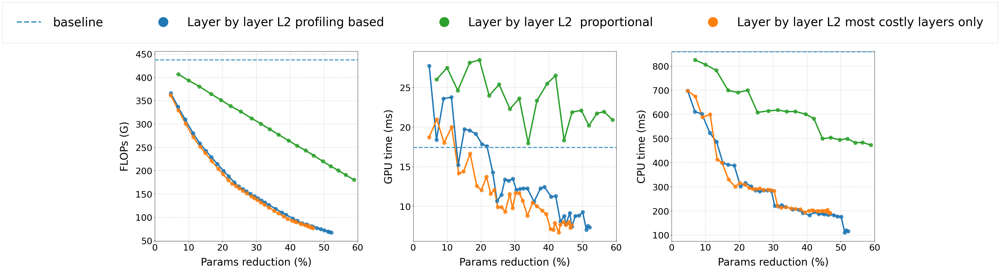

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D

# ── MUCH BIGGER GLOBAL FONTS ─────────────────────────────────────────────────
mpl.rcParams.update({
    "font.size": 40,
    "axes.titlesize": 32,
    "axes.labelsize": 30,
    "xtick.labelsize": 26,
    "ytick.labelsize": 26,
    "legend.fontsize": 40,
    "figure.titlesize": 32,
})

MAX_X = 60.0

STRATEGIES = list(LABEL_MAP.keys())

AGG_FN         = "median"
ENFORCE_MONO_X = True
SCATTER_ALPHA  = 0.8

# ── BIGGER SCATTER POINTS AND LINES ─────────────────────────────────────────
SCATTER_SIZE = 120
LINE_WIDTH   = 4.0


def _num(s):
    return pd.to_numeric(s, errors="coerce")


def _choose_order_col(df):
    for c in [
        "removed_channels_reported",
        "requested_budget_channels",
        "budget_x"
    ]:
        if c in df.columns and _num(df[c]).notna().any():
            return c
    return None


def _build_connected_line(df_one_strat):

    d = df_one_strat.copy()

    d["x"] = _num(d["x"])
    d["y"] = _num(d["y"])

    d = d.replace([np.inf, -np.inf], np.nan)
    d = d.dropna(subset=["x", "y"])

    d = d[d["x"] <= MAX_X].copy()

    if d.empty:
        return None

    oc = _choose_order_col(d)

    if oc is None:

        line = d.sort_values("x")[["x", "y"]].copy()

    else:

        d[oc] = _num(d[oc])

        d = d.dropna(subset=[oc])

        if d.empty:
            return None

        g = getattr(
            d.groupby(oc)[["x", "y"]],
            AGG_FN
        )().reset_index().sort_values(oc)

        line = g[["x", "y"]].copy()

    if ENFORCE_MONO_X and len(line) >= 2:
        line["x"] = np.maximum.accumulate(line["x"].values)

    return line


def _panel(ax, df, ylabel, baseline=None):

    for strat in STRATEGIES:

        color = COLOR_MAP.get(strat)

        dt = df[df["pruning_strategy"] == strat].copy()

        dt["x"] = _num(dt["x"])
        dt["y"] = _num(dt["y"])

        dt = dt.replace([np.inf, -np.inf], np.nan)
        dt = dt.dropna(subset=["x", "y"])

        dt = dt[dt["x"] <= MAX_X].copy()

        if dt.empty:
            continue

        # ── BIGGER COLORED CIRCLES IN PLOT ──────────────────────────────────
        ax.scatter(
            dt["x"],
            dt["y"],
            s=SCATTER_SIZE,
            alpha=SCATTER_ALPHA,
            color=color,
            label=LABEL_MAP.get(strat, strat),
            zorder=3
        )

        line = _build_connected_line(dt)

        if line is not None and len(line) >= 2:

            ax.plot(
                line["x"],
                line["y"],
                linewidth=LINE_WIDTH,
                color=color,
                zorder=2
            )

    if baseline is not None:

        ax.axhline(
            float(baseline),
            linestyle="--",
            linewidth=3.0,
            color="#4393c3",
            zorder=4
        )

    # ── MUCH BIGGER AXIS LABELS ─────────────────────────────────────────────
    ax.set_xlabel(
        "Params reduction (%)",
        fontsize=30,
        labelpad=15
    )

    ax.set_ylabel(
        ylabel,
        fontsize=30,
        labelpad=15
    )

    # ── BIGGER TICKS ────────────────────────────────────────────────────────
    ax.tick_params(axis='both', which='major', labelsize=26)

    ax.grid(
        True,
        linestyle="--",
        linewidth=1.0,
        alpha=0.6
    )

    ax.set_xlim(0, MAX_X)


# ── Build fl ─────────────────────────────────────────────────────────────────
fl = gplot.copy()

fl["x"] = _num(fl["params_reduction_pct"]).clip(0, 100)

fl["y"] = _num(fl["flops_g_pruned_recomputed"])

baseline_flops_g_val = baseline_flops_g


# ── Build gpu ────────────────────────────────────────────────────────────────
gpu = df_latency_all.copy()

right = df_runs[
    ["log_path", "params_reduction_pct"]
].drop_duplicates("log_path")

gpu = gpu.merge(right, on="log_path", how="left")

gpu["x"] = _num(gpu["params_reduction_pct"]).clip(0, 100)

gpu["y"] = _num(gpu["lat_ms_p50"])


# ── Build cpu ────────────────────────────────────────────────────────────────
cpu = df_latency_cpu.copy()

cpu = cpu.merge(right, on="log_path", how="left")

cpu["x"] = _num(cpu["params_reduction_pct"]).clip(0, 100)

cpu["y"] = _num(cpu["lat_ms_p50"])


# ── MUCH BIGGER FIGURE ───────────────────────────────────────────────────────
fig, axes = plt.subplots(
    1,
    3,
    figsize=(32, 10),
    sharex=True
)

_panel(
    axes[0],
    fl,
    "FLOPs (G)",
    baseline=baseline_flops_g_val
)

_panel(
    axes[1],
    gpu,
    "GPU time (ms)",
    baseline=baseline_lat_p50
)

_panel(
    axes[2],
    cpu,
    "CPU time (ms)",
    baseline=baseline_cpu_p50
)


# ── MUCH BIGGER LEGEND CIRCLES ──────────────────────────────────────────────
legend_handles = [
    Line2D(
        [0],
        [0],
        marker='o',
        color='w',
        markerfacecolor=COLOR_MAP[s],
        markersize=30,   # BIGGER LEGEND CIRCLES
        label=LABEL_MAP[s]
    )
    for s in STRATEGIES
]

baseline_handle = Line2D(
    [0],
    [0],
    linestyle="--",
    linewidth=4.0,
    color="#4393c3",
    label="baseline"
)


# ── MUCH BIGGER LEGEND TEXT + BOX ───────────────────────────────────────────
fig.legend(
    handles=[baseline_handle] + legend_handles,

    loc="upper center",

    ncol=len(STRATEGIES) + 1,

    bbox_to_anchor=(0.5, 1.16),

    frameon=True,

    edgecolor="#cccccc",

    fancybox=False,

    fontsize=35,   # BIGGER LEGEND WRITING

    handletextpad=1.0,

    columnspacing=4.0,

    borderpad=1.2
)

plt.tight_layout()

plt.savefig(
    "carvana_l2_final.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "carvana_l2_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()